[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/EN/chapter8_seminar_notebook.ipynb)

# Modelling Financial Markets — Seminar 8: Backtesting and Evaluating Risk Forecasts

*Seminar notebook. Daniel Traian Pele, Antoaneta Amza — Bucharest University of Economic Studies.*

- **Part A**: numerical check of the ten derivations.
- **Part B**: backtesting and inference on the S&P 500, BET, Bitcoin and EUR/RON.
- **Part C**: open questions and Artificial Intelligence (AI) critique (C2: a provisional model for a Romanian trading portfolio; C1: critique of an AI answer; C3: Expected Shortfall (ES) backtests in R).
- The seminar comes before Lecture 8; the slides open with a short primer (Kupiec, Christoffersen, durations and Dynamic Quantile (DQ), traffic light, $Z_2$, scores and Diebold–Mariano).
- **In class**: A1, A2, A3, A4, B1, B2, C1. **After the lecture**: B3, B4 and B5; the other sections are optional extensions.
- **[Solved]** problems are fully worked out (code and output); **[Proposed]** problems have an empty cell for you: their solutions are discussed in the seminar.
- Worked examples to follow: A1 for A5; A2 for A6; A7 for A8; A4 for A9; A3 and B1 for B5; B4 for B6; B3 for B7; B2 for B8; B1 for B9; A2 and A3 for C1.
- Full statements (context, numbered sub-tasks 1, 2, ..., what to report) are in the Seminar 8 slides; each problem below gives its inputs and the question to answer.

> The solutions are discussed in the seminar.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_8'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261021T110004-d6af62


In [ ]:
import os
import sys
import subprocess
try:
    import arch  # GARCH estimation
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'], check=True)
import pickle
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats, optimize
from numpy.lib.stride_tricks import sliding_window_view
import warnings
warnings.filterwarnings('ignore')

## Data and forecast panel

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# use the local copy of the course data when running inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')

# name -> (symbol, start date); indices/crypto: closing price
SOURCES = {
    'sp500':  ('GSPC.INDX', '1990-01-01'),
    'bet':    ('BET', '1997-09-19'),
    'btc':    ('BTC-USD.CC', '2014-09-17'),
    'eurron': ('REF:EUR', '2005-07-01'),        # BNR reference rate, since the introduction of the new leu
}
LABELS = {'sp500': 'S&P 500', 'bet': 'BET', 'btc': 'Bitcoin', 'eurron': 'EUR/RON'}
ASSETS = list(SOURCES)

_CACHE = {}


def read_market(symbol):
    """Read data/market/<SYMBOL>.csv locally or from the GitHub repository."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end='2026-09-18'):
    """Official RON reference rate published by the BNR (yearly XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    import re
    import urllib.request
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_price(name):
    """Price series (close) of the asset."""
    symbol, start = SOURCES[name]
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start)
    p = read_market(symbol)['close'].loc[start:]
    return p[p > 0].dropna()


def load_returns(name):
    """Daily log returns on the series' own calendar."""
    return np.log(load_price(name)).diff().dropna()


# =============================================================================
# VaR / ES FORECASTS ON A ROLLING WINDOW (one day ahead)
# =============================================================================
W = 1000                       # estimation window (observations)
REFIT = 20                     # GARCH / t / EVT parameters are re-estimated every 20 days
LEVELS = (0.01, 0.025, 0.05)   # tail probabilities: VaR 1%, VaR 2.5%, VaR 5%
A_ES = 0.025                   # ES 2.5% (FRTB)
K_TAIL = int(np.ceil(A_ES * W))   # number of tail order statistics (Z2 simulation)
MODELS = ['HS', 'Normal', 'Student-t', 'GARCH-t', 'FHS', 'GARCH-EVT']
EVAL_FROM = '2007-01-01'       # first possible evaluation day
EVT_Q = 0.90                   # POT threshold: 90% quantile of the standardised losses


def t_std_q(nu, a):
    """Quantile of order 1-a of the standardised Student-t distribution (unit variance)."""
    return stats.t.ppf(1 - a, nu) * np.sqrt((nu - 2) / nu)


def t_std_es(nu, a):
    """ES at level 1-a of the standardised Student-t distribution (unit variance)."""
    q = stats.t.ppf(1 - a, nu)
    return stats.t.pdf(q, nu) / a * (nu + q ** 2) / (nu - 1) * np.sqrt((nu - 2) / nu)


import numpy as np

class NoAdmissibleInitialFit(RuntimeError):
    """The fitted candidate was rejected and no prior admissible fit exists."""

def garch_fit(x, prev=None):
    """Same Student-t GARCH(1,1); unresolved boundary fits cannot update parameters.

    The numerical band diagnoses precision near alpha+beta=1. It neither clamps
    parameters nor changes the maintained finite-variance restriction alpha+beta<1.
    Only a previously clearly admissible fit may be reused, with status reported.
    """
    garch_fit.last_diagnostic = None
    from arch import arch_model
    resolution = 1e-8
    c = 1 / x.std()
    res = arch_model(c * x, mean='Constant', vol='GARCH', p=1, q=1, dist='t',
                     rescale=False).fit(disp='off', show_warning=False)
    mu, om, a, b, nu = res.params.values
    finite = np.isfinite([mu, om, a, b, nu, res.loglikelihood]).all()
    gap = 1-a-b
    if res.convergence_flag != 0 or not finite or abs(mu)>=1 or om<=0 or a<0 or b<0 or nu<=2:
        status = 'fit-invalid'
    elif abs(gap) <= resolution:
        status = 'numeric-unidentified'
    elif gap < 0:
        status = 'finite-variance-inadmissible'
    else:
        status = 'clearly-admissible'
    garch_fit.last_diagnostic = {
        'status':status, 'flag':int(res.convergence_flag),
        'raw_persistence':float(a+b) if np.isfinite(a+b) else None,
        'loglikelihood':float(res.loglikelihood) if np.isfinite(res.loglikelihood) else None,
        'resolution':resolution,
        'candidate_params_scaled':[float(v) if np.isfinite(v) else None for v in (mu,om,a,b,nu)],
        'fallback':False}
    if status=='clearly-admissible':
        return mu/c, om/c**2, a, b, nu
    if prev is None:
        garch_fit.last_diagnostic['fallback'] = False
        raise NoAdmissibleInitialFit(f'GARCH fit is {status}; no earlier clearly admissible parameters are available')
    pm, po, pa, pb, pn = prev
    if not (np.isfinite(prev).all() and po>0 and pa>=0 and pb>=0 and 1-pa-pb>resolution and pn>2):
        raise RuntimeError('Previous GARCH parameters are not clearly admissible; cannot use fallback')
    garch_fit.last_diagnostic['fallback'] = True
    return prev


def garch_filter(x, mu, om, a, b, s2_0):
    """Conditional variance: s2[t] uses only x[:t]; the last element is the forecast."""
    e2 = (x - mu) ** 2
    s2 = np.empty(len(x) + 1)
    s2[0] = s2_0
    for t in range(len(x)):
        s2[t + 1] = om + a * e2[t] + b * s2[t]
    return s2


def gpd_tail(y, a_list, q=EVT_Q):
    """EVT (POT): GPD on the excesses of standardised losses over the q quantile; VaR/ES at levels 1-a."""
    u = np.quantile(y, q)
    exc = y[y > u] - u
    xi, _, beta = stats.genpareto.fit(exc, floc=0)
    pu = len(exc) / len(y)
    var = {a: u + beta / xi * ((a / pu) ** (-xi) - 1) for a in a_list}
    es = {a: (var[a] + beta - xi * u) / (1 - xi) for a in a_list}
    return dict(u=u, xi=xi, beta=beta, pu=pu, var=var, es=es)


def gpd_cdf(y, g, emp):
    """EVT distribution function: empirical below the threshold, GPD above it."""
    if y <= g['u']:
        return np.mean(emp <= y)
    base = 1 + g['xi'] * (y - g['u']) / g['beta']
    return 1.0 if base <= 0 else 1 - g['pu'] * base ** (-1 / g['xi'])


def rolling_forecasts(r, eval_from=EVAL_FROM, w=W, refit=REFIT):
    """One-day-ahead VaR (LEVELS) and ES (A_ES) forecasts for the loss L = -r, for all models.

    Result: dict model -> DataFrame (index = forecast day) with columns
    VaR1, VaR2.5, VaR5, ES2.5, ES1, pit (F(L_t)), scale, mu, plus information for tail simulation.
    GARCH-dependent models retain NaN forecast rows until an admissible initial
    fit exists. Consumers must check completeness before computing any metric."""
    r = r.dropna()
    L = -r.values
    idx = r.index
    start = max(w, int(np.searchsorted(idx, pd.Timestamp(eval_from))))
    T = len(r) - start
    if T <= 0:
        raise ValueError('No evaluation rows after the estimation window')
    days = idx[start:]
    out = {m: {k: np.full(T, np.nan) for k in ['VaR1', 'VaR2.5', 'VaR5', 'ES2.5', 'ES1', 'pit', 'scale', 'mu', 'nu',
                                               'u', 'xi', 'beta', 'pu']} for m in MODELS}
    tails = {m: np.full((T, K_TAIL), np.nan) for m in ('HS', 'FHS')}
    lev = {0.01: 'VaR1', 0.025: 'VaR2.5', 0.05: 'VaR5'}
    Lcur = L[start:]

    # --- HS and Normal: vectorised over windows
    win = sliding_window_view(L[:-1], w)[start - w:]          # window for day t: L[t-w:t]
    srt = np.sort(win, axis=1)
    o = out['HS']
    for a, k in lev.items():
        o[k] = np.quantile(win, 1 - a, axis=1)
    for a, k in ((0.025, 'ES2.5'), (0.01, 'ES1')):
        v = np.quantile(win, 1 - a, axis=1)
        o[k] = np.nanmean(np.where(win >= v[:, None], win, np.nan), axis=1)
    o['pit'] = (np.sum(win < Lcur[:, None], axis=1) + 0.5 * np.sum(win == Lcur[:, None], axis=1)) / w
    o['scale'] = win.std(axis=1, ddof=1)
    o['mu'] = np.zeros(T)
    tails['HS'] = srt[:, -K_TAIL:]
    mu_w, sd_w = -win.mean(axis=1), win.std(axis=1, ddof=1)     # mean of returns, standard deviation
    o = out['Normal']
    for a, k in lev.items():
        o[k] = -mu_w + sd_w * stats.norm.ppf(1 - a)
    for a, k in ((0.025, 'ES2.5'), (0.01, 'ES1')):
        o[k] = -mu_w + sd_w * stats.norm.pdf(stats.norm.ppf(1 - a)) / a
    o['pit'] = stats.norm.cdf((Lcur + mu_w) / sd_w)
    o['scale'], o['mu'] = sd_w, mu_w

    # --- models re-estimated every `refit` days
    prev = None
    source_origin = None
    refit_records = []
    daily_status = np.empty(T, dtype=object)
    daily_age = np.full(T, None, dtype=object)
    daily_source = np.empty(T, dtype=object)
    daily_estimation_end = np.empty(T, dtype=object)
    daily_fallback = np.empty(T, dtype=bool)
    for b0 in range(0, T, refit):
        t0 = start + b0
        b1 = min(T, b0 + refit)
        x = r.values[t0 - w:t0]
        # unconditional Student-t: degrees of freedom, location and scale by MLE
        nu_t, loc_t, sc_t = stats.t.fit(x)
        nu_t = max(nu_t, 2.2)
        sd_t = sc_t * np.sqrt(nu_t / (nu_t - 2))                # implied standard deviation
        for t in range(b0, b1):
            Lt = Lcur[t]
            # unconditional Student-t
            o = out['Student-t']
            for a, k in lev.items():
                o[k][t] = -loc_t + sd_t * t_std_q(nu_t, a)
            o['ES2.5'][t] = -loc_t + sd_t * t_std_es(nu_t, 0.025)
            o['ES1'][t] = -loc_t + sd_t * t_std_es(nu_t, 0.01)
            o['pit'][t] = stats.t.cdf((Lt + loc_t) / sc_t, nu_t)
            o['scale'][t], o['mu'][t], o['nu'][t] = sd_t, loc_t, nu_t
        # GARCH(1,1)-t
        try:
            prev = garch_fit(x, prev)
        except NoAdmissibleInitialFit:
            if prev is not None:
                raise RuntimeError('Initial-fit exception with an existing prior')
            record = dict(garch_fit.last_diagnostic)
            record.update(forecast_available=False,refit_date=str(days[b0].date()),
                          estimation_end_date=str(idx[t0-1].date()),
                          parameter_source_date=None, parameter_estimation_end_date=None,
                          age_at_refit_trading_rows=None)
            refit_records.append(record)
            daily_status[b0:b1] = record['status']
            daily_source[b0:b1] = None
            daily_estimation_end[b0:b1] = None
            daily_fallback[b0:b1] = False
            continue
        fit_record = dict(garch_fit.last_diagnostic)
        if not fit_record['fallback']:
            source_origin = b0
        if source_origin is None:
            raise RuntimeError('No admissible source fit for rolling forecasts')
        fit_record.update(forecast_available=True,refit_date=str(days[b0].date()),
                          estimation_end_date=str(idx[t0-1].date()),
                          parameter_source_date=str(days[source_origin].date()),
                          parameter_estimation_end_date=str(idx[start+source_origin-1].date()),
                          age_at_refit_trading_rows=int(b0-source_origin))
        refit_records.append(fit_record)
        daily_status[b0:b1] = fit_record['status']
        daily_age[b0:b1] = list(range(b0-source_origin,b1-source_origin))
        daily_source[b0:b1] = str(days[source_origin].date())
        daily_fallback[b0:b1] = fit_record['fallback']
        daily_estimation_end[b0:b1] = str(idx[start+source_origin-1].date())
        mu, om, al, be, nu = prev
        nu = max(nu, 2.2)
        xx = r.values[t0 - w:t0 + (b1 - b0)]
        s2 = garch_filter(xx, mu, om, al, be, np.var(x[:50]))
        z = (x - mu) / np.sqrt(s2[:w])
        y = np.sort(-z)                                         # standardised losses
        g = gpd_tail(y, (0.01, 0.025, 0.05))
        for t in range(b0, b1):
            j = w + (t - b0)
            sig = np.sqrt(s2[j])
            Lt = Lcur[t]
            # GARCH-t
            o = out['GARCH-t']
            for a, k in lev.items():
                o[k][t] = -mu + sig * t_std_q(nu, a)
            o['ES2.5'][t] = -mu + sig * t_std_es(nu, 0.025)
            o['ES1'][t] = -mu + sig * t_std_es(nu, 0.01)
            o['pit'][t] = stats.t.cdf((Lt + mu) / sig / np.sqrt((nu - 2) / nu), nu)
            o['scale'][t], o['mu'][t], o['nu'][t] = sig, mu, nu
            # FHS: empirical quantiles of the standardised losses
            o = out['FHS']
            for a, k in lev.items():
                o[k][t] = -mu + sig * np.quantile(y, 1 - a)
            for a, k in ((0.025, 'ES2.5'), (0.01, 'ES1')):
                q = np.quantile(y, 1 - a)
                o[k][t] = -mu + sig * y[y >= q].mean()
            o['pit'][t] = np.mean(y < (Lt + mu) / sig)
            o['scale'][t], o['mu'][t] = sig, mu
            tails['FHS'][t] = -mu + sig * y[-K_TAIL:]
            # GARCH-EVT
            o = out['GARCH-EVT']
            for a, k in lev.items():
                o[k][t] = -mu + sig * g['var'][a]
            o['ES2.5'][t] = -mu + sig * g['es'][0.025]
            o['ES1'][t] = -mu + sig * g['es'][0.01]
            o['pit'][t] = gpd_cdf((Lt + mu) / sig, g, y)
            o['scale'][t], o['mu'][t] = sig, mu
            o['u'][t], o['xi'][t], o['beta'][t], o['pu'][t] = g['u'], g['xi'], g['beta'], g['pu']
    res = {}
    for m in MODELS:
        df = pd.DataFrame(out[m], index=days)
        df['L'] = Lcur
        res[m] = df
    # Metadata do not enter any forecast, loss, statistic, or common-sample selection.
    daily = pd.DataFrame({'forecast_available':[a is not None for a in daily_age], 'fit_status':daily_status, 'fallback':daily_fallback,
                          'parameter_age_trading_rows':daily_age,
                          'parameter_source_date':daily_source,'parameter_estimation_end_date':daily_estimation_end}, index=days)
    counts = {s:sum(row['status']==s for row in refit_records) for s in
              ['clearly-admissible','numeric-unidentified','finite-variance-inadmissible','fit-invalid']}
    summary = {'policy':'finite-variance-resolution-1e-8-v1', 'refits_by_status':counts,
               'fallback_forecast_days':int(daily_fallback.sum()),
               'max_parameter_age_trading_rows':max((int(a) for a in daily_age if a is not None), default=None),
               'age_definition':'trading rows since source refit origin; variance/residuals filtered on current data',
               'no_previous_fit':'dependent forecasts missing; original calendar and independent forecasts preserved',
               'unavailable_forecast_days':sum(a is None for a in daily_age),
               'unavailable_refits':sum(not row['forecast_available'] for row in refit_records)}
    for model in ['GARCH-t','FHS','GARCH-EVT']:
        res[model].attrs['garch_numerics'] = summary
    rolling_forecasts.last_diagnostics = {'summary':summary,'refits':refit_records,'daily':dict(forecast_date=[str(d.date()) for d in days],**daily.to_dict(orient='list'))}
    print('GARCH numerical status:', summary)
    if summary['unavailable_forecast_days']:
        print('GARCH-dependent forecasts unavailable on', summary['unavailable_forecast_days'], 'original calendar rows; full-sample metrics require completeness checks.')
    if daily_fallback.any():
        print('Fallback parameters are stale; filtering still uses current observations.')
        spells = daily.loc[daily.fallback].groupby('parameter_source_date',sort=True).agg(
            fallback_days=('fallback','size'), max_age=('parameter_age_trading_rows','max'))
        print(spells.to_string())
    return res, tails


def get_forecasts(name):
    """Forecast cache tied to exact input, configuration, code and package versions."""
    import hashlib, json, types, sys
    from importlib.metadata import version
    r = load_returns(name)
    def code_record(code):
        def const(x):
            if isinstance(x, types.CodeType): return code_record(x)
            if isinstance(x, bytes): return {'bytes':x.hex()}
            if isinstance(x, tuple): return [const(v) for v in x]
            if isinstance(x, frozenset): return {'frozenset':sorted([const(v) for v in x],key=lambda v:json.dumps(v,sort_keys=True))}
            if x is None or isinstance(x,(str,int,float,bool)): return x
            return repr(x)
        return {'bytecode':code.co_code.hex(),'constants':[const(x) for x in code.co_consts],
                'names':code.co_names,'varnames':code.co_varnames,
                'argcount':code.co_argcount,'kwonlyargcount':code.co_kwonlyargcount}
    helpers = (garch_fit,garch_filter,rolling_forecasts,gpd_tail,gpd_cdf,t_std_q,t_std_es)
    config = {'policy':'finite-variance-resolution-1e-8-v1','name':name,
              'window':W,'refit':REFIT,'eval_from':EVAL_FROM,'tail_count':K_TAIL,'evt_q':EVT_Q,
              'models':MODELS,'python':sys.version,
              'versions':{p:version(p) for p in ['numpy','scipy','arch','pandas']},
              'code':{f.__name__:{'code':code_record(f.__code__),'defaults':f.__defaults__,'kwdefaults':f.__kwdefaults__} for f in helpers},
              'returns_sha256':hashlib.sha256(np.ascontiguousarray(r.values,dtype='<f8').tobytes()).hexdigest(),
              'dates_sha256':hashlib.sha256(np.ascontiguousarray(r.index.asi8,dtype='<i8').tobytes()).hexdigest()}
    fingerprint=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
    path=os.path.join(tempfile.gettempdir(),f'mfm_ch8_fc_v2_{fingerprint}.pkl')
    if os.path.exists(path):
        with open(path,'rb') as f: stored=pickle.load(f)
        if stored.get('fingerprint')==fingerprint:
            fc=stored['forecasts']
            report=stored.get('garch_numerics')
            if (report and report['summary']['policy']==config['policy'] and all(fc[0][m].attrs.get('garch_numerics',{}).get('policy')==config['policy'] for m in ['GARCH-t','FHS','GARCH-EVT'])):
                get_forecasts.last_cache_identity=fingerprint
                get_forecasts.last_diagnostics=report
                rolling_forecasts.last_diagnostics=report
                print('GARCH numerical status:',report['summary'])
                if report['summary']['fallback_forecast_days']:
                    print('Fallback parameters are stale; filtering still uses current observations.')
                    daily=pd.DataFrame(report['daily'])
                    print(daily.loc[daily.fallback].groupby('parameter_source_date').agg(
                        fallback_days=('fallback','size'),max_age=('parameter_age_trading_rows','max')).to_string())
                return fc
    fc=rolling_forecasts(r)
    report=rolling_forecasts.last_diagnostics
    get_forecasts.last_diagnostics=report
    stored={'fingerprint':fingerprint,'configuration':config,'forecasts':fc,'garch_numerics':report}
    temporary=None
    try:
        with tempfile.NamedTemporaryFile(mode='wb',dir=tempfile.gettempdir(),delete=False) as f:
            temporary=f.name
            pickle.dump(stored,f)
        os.replace(temporary,path)
    finally:
        if temporary and os.path.exists(temporary):os.unlink(temporary)
    get_forecasts.last_cache_identity=fingerprint
    return fc


# =============================================================================
# VaR TESTS
# =============================================================================
def kupiec(hits, p):
    """Kupiec POF test: LR_uc ~ chi2(1)."""
    hits = np.asarray(hits, int)
    T, x = len(hits), hits.sum()
    ph = x / T
    ll0 = (T - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (T - x) * np.log(1 - ph) + x * np.log(ph) if 0 < x < T else 0.0
    lr = -2 * (ll0 - ll1)
    return dict(T=T, x=int(x), rate=ph, LR=lr, p=stats.chi2.sf(lr, 1))


def transitions(hits):
    """Counts of the transitions n00, n01, n10, n11 of the hit sequence."""
    h = np.asarray(hits, int)
    a, b = h[:-1], h[1:]
    return dict(n00=int(np.sum((a == 0) & (b == 0))), n01=int(np.sum((a == 0) & (b == 1))),
                n10=int(np.sum((a == 1) & (b == 0))), n11=int(np.sum((a == 1) & (b == 1))))


def christoffersen_from_counts(n00, n01, n10, n11, p):
    """LR_ind (independence, first-order Markov chain) and LR_cc = LR_uc + LR_ind."""
    def xlogy(n, q):
        return n * np.log(q) if n > 0 else 0.0
    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    l_ind = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    l_0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    lr_ind = -2 * (l_0 - l_ind)
    T, x = n00 + n01 + n10 + n11, n01 + n11
    lr_uc = -2 * (xlogy(T - x, 1 - p) + xlogy(x, p) - xlogy(T - x, 1 - pi) - xlogy(x, pi))
    lr_cc = lr_uc + lr_ind
    return dict(pi01=pi01, pi11=pi11, pi=pi, LR_ind=lr_ind, p_ind=stats.chi2.sf(lr_ind, 1),
                LR_uc=lr_uc, LR_cc=lr_cc, p_cc=stats.chi2.sf(lr_cc, 2))


def christoffersen(hits, p):
    return christoffersen_from_counts(**transitions(hits), p=p)


def durations(hits):
    """Durations (days) between breaches, with censoring flags for the first and last duration."""
    h = np.asarray(hits, int)
    pos = np.flatnonzero(h)
    if len(pos) == 0:
        return np.array([len(h)]), 1, 1
    D = np.diff(np.r_[-1, pos, len(h) - 1 if h[-1] == 0 else pos[-1]])
    D = D[D > 0]
    c1 = 1 if h[0] == 0 else 0
    cn = 1 if h[-1] == 0 else 0
    return D.astype(float), c1, cn


def duration_test(hits):
    """Christoffersen-Pelletier (2004) duration test: continuous Weibull approximation, H0: b = 1 (memoryless)."""
    D, c1, cn = durations(hits)
    if len(D) < 3:
        return dict(b=np.nan, LR=np.nan, p=np.nan, n=len(D))

    def nll(par, fix_b=False):
        a = np.exp(par[0])
        b = 1.0 if fix_b else np.exp(par[1])
        lf = np.log(b) + b * np.log(a) + (b - 1) * np.log(D) - (a * D) ** b
        ls = -(a * D) ** b
        ll = lf.copy()
        if c1:
            ll[0] = ls[0]
        if cn:
            ll[-1] = ls[-1]
        return -ll.sum()
    a0 = np.log(1 / D.mean())
    r1 = optimize.minimize(nll, [a0, 0.0], method='Nelder-Mead', options=dict(xatol=1e-8, fatol=1e-10, maxiter=4000))
    r0 = optimize.minimize(lambda p: nll(p, True), [a0], method='Nelder-Mead')
    lr = max(2 * (r0.fun - r1.fun), 0.0)
    return dict(b=float(np.exp(r1.x[1])), LR=lr, p=stats.chi2.sf(lr, 1), n=len(D))


# =============================================================================
# ES TESTS
# =============================================================================
def mcneil_frey(L, var, es, scale, B=5000, seed=0):
    """Exceedance residuals (L - ES)/sigma on days with L > VaR; H0: mean 0, H1: mean > 0 (i.i.d. bootstrap)."""
    hit = L > var
    e = ((L - es) / scale)[hit]
    n = len(e)
    if n < 3:
        return dict(n=n, mean=np.nan, t=np.nan, p=np.nan)
    tstat = e.mean() / (e.std(ddof=1) / np.sqrt(n))
    rng = np.random.default_rng(seed)
    ec = e - e.mean()
    bs = rng.choice(ec, (B, n), replace=True)
    tb = bs.mean(1) / (bs.std(1, ddof=1) / np.sqrt(n))
    return dict(n=n, mean=e.mean(), t=tstat, p=float(np.mean(tb >= tstat)))


def acerbi_szekely(L, var, es, a=A_ES):
    """Acerbi-Szekely (2014) Z1 and Z2 statistics, with losses positive."""
    hit = L > var
    T, n = len(L), hit.sum()
    z1 = 1 - np.mean(L[hit] / es[hit]) if n > 0 else np.nan
    z2 = 1 - np.sum(L[hit] / es[hit]) / (T * a)
    return z1, z2


def tail_sampler(df, model, tails, U):
    """Inverse loss distribution function for levels U > 1 - A_ES (matrix T x M)."""
    mu, sc = df['mu'].values[:, None], df['scale'].values[:, None]
    if model in ('HS', 'FHS'):
        k = np.clip(np.ceil((U - (1 - A_ES)) / A_ES * K_TAIL).astype(int) - 1, 0, K_TAIL - 1)
        return np.take_along_axis(tails[model], k, axis=1)
    if model == 'Normal':
        return -mu + sc * stats.norm.ppf(U)
    if model in ('Student-t', 'GARCH-t'):
        nu = df['nu'].values[:, None]
        return -mu + sc * stats.t.ppf(U, nu) * np.sqrt((nu - 2) / nu)
    if model == 'GARCH-EVT':
        u, xi, be, pu = (df[c].values[:, None] for c in ('u', 'xi', 'beta', 'pu'))
        return -mu + sc * (u + be / xi * (((1 - U) / pu) ** (-xi) - 1))
    raise ValueError(model)


def du_escanciano(pit, a=A_ES, lags=5):
    """Du-Escanciano (2017): cumulative violation H_t = (1/a)(u_t - (1-a)) 1{u_t > 1-a};
    unconditional test U_ES ~ N(0,1) and conditional test C_ES (Box-Pierce, chi2(lags))."""
    u = np.clip(np.asarray(pit), 0, 1)
    H = (u - (1 - a)) / a * (u > 1 - a)
    T = len(H)
    U = np.sqrt(T) * (H.mean() - a / 2) / np.sqrt(a * (1 / 3 - a / 4))
    hc = H - a / 2
    g0 = np.mean(hc ** 2)
    rho = np.array([np.mean(hc[j:] * hc[:-j]) / g0 for j in range(1, lags + 1)])
    C = T * np.sum(rho ** 2)
    return dict(meanH=H.mean(), U=U, pU=2 * stats.norm.sf(abs(U)), C=C, pC=stats.chi2.sf(C, lags))


# =============================================================================
# FZ0 LOSS, DIEBOLD-MARIANO, MCS
# =============================================================================
def fz0(L, var, es, a=A_ES):
    """FZ0 loss (Patton, Ziegel & Chen, 2019), written for positive losses:
    FZ0 = (1/(a ES)) 1{L > VaR} (L - VaR) + VaR/ES + log(ES) - 1  (ES > 0)."""
    return (L > var) * (L - var) / (a * es) + var / es + np.log(es) - 1


def pinball(L, var, a):
    """Quantile (tick) loss: (1{L > VaR} - a)(L - VaR) >= 0, minimised in expectation by the 1-a quantile."""
    return ((L > var).astype(float) - a) * (L - var)


def nw_var(d, lags=None):
    """Long-run variance (Newey-West, Bartlett kernel)."""
    d = np.asarray(d) - np.mean(d)
    T = len(d)
    if lags is None:
        lags = int(np.floor(4 * (T / 100) ** (2 / 9)))
    v = np.mean(d ** 2)
    for j in range(1, lags + 1):
        v += 2 * (1 - j / (lags + 1)) * np.dot(d[j:], d[:-j]) / T     # autocovariance with divisor T (PSD)
    return v


def diebold_mariano(la, lb, lags=None):
    """DM = mean(d) / sqrt(LRV/T), d = la - lb; negative => A has the lower average loss."""
    d = np.asarray(la) - np.asarray(lb)
    dm = d.mean() / np.sqrt(nw_var(d, lags) / len(d))
    return dict(dbar=d.mean(), DM=dm, p=2 * stats.norm.sf(abs(dm)))


# =============================================================================
# CONFORMAL PREDICTION FOR VaR
# =============================================================================
def conformal_var(r, a=0.01, n_cal=250, n_sd=250, gamma=0.005, eval_from=EVAL_FROM):
    """Rolling split conformal VaR and ACI (Gibbs & Candes, 2021).

    Nonconformity score: s_t = L_t / sd_t, sd_t = standard deviation of the previous n_sd returns.
    VaR_t = sd_t * the order statistic k = ceil((n+1)(1-a)) of the last n_cal scores (+inf if k > n).
    ACI: a_{t+1} = a_t + gamma (a - err_t); if the required rank exceeds n, VaR = +inf; if it is not positive
    (a_t >= 1), VaR = -inf, so a breach is certain. With both conventions the long-run bound of Gibbs & Candes
    holds for any sequence: |mean(err) - a| <= (max(a_1, 1 - a_1) + gamma) / (gamma T).
    Rolling-standardised scores are only approximately exchangeable, even for i.i.d. returns."""
    r = r.dropna()
    L = -r.values
    sd = pd.Series(r.values).rolling(n_sd).std().shift(1).values   # only information up to t-1
    s = L / sd
    start = max(n_sd + n_cal + 1, int(np.searchsorted(r.index, pd.Timestamp(eval_from))))
    T = len(r) - start
    var_s, var_a, a_path = np.empty(T), np.empty(T), np.empty(T)
    at = a
    for i in range(T):
        t = start + i
        cal = np.sort(s[t - n_cal:t])
        k = int(np.ceil((n_cal + 1) * (1 - a)))
        var_s[i] = np.inf if k > n_cal else sd[t] * cal[k - 1]
        ka = int(np.ceil((n_cal + 1) * (1 - at)))
        # extended lower quantile: rank > n -> +inf (no breach possible); rank <= 0 (alpha_t >= 1) -> -inf (sure breach)
        var_a[i] = np.inf if ka > n_cal else (-np.inf if ka < 1 else sd[t] * cal[ka - 1])
        a_path[i] = at
        err = float(L[t] > var_a[i])
        at = at + gamma * (a - err)
    return pd.DataFrame({'L': L[start:], 'VaR_split': var_s, 'VaR_aci': var_a, 'alpha_t': a_path,
                         'sd': sd[start:]}, index=r.index[start:])


def regimes(r, idx, n=20, q=0.90, w=W, min_obs=250):
    """Crisis days: volatility over the n days before day t (excluding day t) above the q quantile of the
    same volatilities over the last w days (the models' estimation window, at least min_obs values);
    the indicator and its threshold use returns up to t-1 only, so they are known ex ante."""
    rv = r.rolling(n).std().shift(1)
    cut = rv.rolling(w, min_periods=min_obs).quantile(q)
    return (rv > cut).reindex(idx).fillna(False).astype(bool)

## Style

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Brand colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal = '#17A2B8'
MCOL = {'HS': Teal, 'Normal': Amber, 'Student-t': Purple, 'GARCH-t': MainBlue, 'FHS': Forest, 'GARCH-EVT': IDAred}
PV_CMAP = LinearSegmentedColormap.from_list('pv', [IDAred, '#F4B6B6', '#FFFFFF', '#BFD8BF', Forest])


_FC = {}


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def pv_heatmap(ax, P, fmt='{:.2f}', title=None):
    """Heat map of p-values: red = rejection, green = no rejection (log scale)."""
    Z = np.log10(np.clip(P.values.astype(float), 1e-4, 1))
    ax.imshow(Z, cmap=PV_CMAP, vmin=-4, vmax=0, aspect='auto')
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            v = P.values[i, j]
            txt = '<.001' if v < 0.001 else (f'{v:.3f}' if v < 0.01 else fmt.format(v))
            ax.text(j, i, txt, ha='center', va='center', fontsize=7)
    ax.set_xticks(range(P.shape[1]), P.columns, fontsize=7.5)
    ax.set_yticks(range(P.shape[0]), P.index, fontsize=7.5)
    for s in ax.spines.values():
        s.set_visible(False)
    if title:
        ax.set_title(title, fontsize=9)








def save_fig(name):
    """Show the figure; with SAVE_TO_DRIVE = True also save it (PDF and PNG) in OUT_DIR."""
    if globals().get('SAVE_TO_DRIVE', False):
        out = globals().get('OUT_DIR', '.')
        plt.savefig(os.path.join(out, f'{name}.pdf'), bbox_inches='tight', transparent=True)
        plt.savefig(os.path.join(out, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
"""Prototype only: metric eligibility on an externally supplied canonical calendar.
Caller must retain the original model universe; this function cannot establish it.
"""
import numpy as np
import pandas as pd
from pandas.api.types import is_numeric_dtype, is_bool_dtype, is_complex_dtype

def completeness(frame, calendar, columns, losses):
    if isinstance(columns, (str, bytes)):
        raise ValueError('Metric columns must be a sequence, not a bare string')
    columns = list(columns)
    if not columns or any(not isinstance(c, str) or c == 'L' for c in columns) or len(set(columns)) != len(columns):
        raise ValueError('Metric columns must be unique forecast names, excluding L')
    calendar = pd.Index(calendar)
    if len(calendar) == 0 or not calendar.is_unique or not calendar.is_monotonic_increasing:
        raise ValueError('Canonical calendar must be nonempty, unique, ordered')
    if not isinstance(losses, pd.Series) or not losses.index.equals(calendar):
        raise ValueError('Canonical losses must align exactly with the calendar')
    def real_values(series):
        if not is_numeric_dtype(series.dtype) or is_bool_dtype(series.dtype) or is_complex_dtype(series.dtype):
            return None
        return series.to_numpy(dtype=float, na_value=np.nan)
    expected = real_values(losses)
    if expected is None or not np.isfinite(expected).all():
        raise ValueError('Canonical losses must be finite real numbers')
    if not isinstance(frame, pd.DataFrame) or not frame.columns.is_unique or isinstance(frame.columns, pd.MultiIndex):
        return {'eligible': False, 'reason': 'invalid_frame'}
    if not frame.index.equals(calendar):
        return {'eligible': False, 'reason': 'calendar_mismatch'}
    for name in dict.fromkeys(['L'] + columns):
        if name not in frame:
            return {'eligible': False, 'reason': 'missing_column', 'column': name}
        values = real_values(frame[name])
        if values is None or not np.isfinite(values).all():
            return {'eligible': False, 'reason': 'nonfinite_or_nonreal', 'column': name}
        if name == 'L' and not np.array_equal(values, expected):
            return {'eligible': False, 'reason': 'loss_mismatch'}
    return {'eligible': True, 'reason': None}

"""Validate forecast absence against the producer's dated availability record."""
import numpy as np
import pandas as pd
from pandas.api.types import is_numeric_dtype,is_bool_dtype,is_complex_dtype

def validate_forecast_contract(frames,models,calendar,losses,report):
    calendar=pd.Index(calendar)
    if not calendar.is_unique or not calendar.is_monotonic_increasing or not len(calendar):
        raise ValueError('Invalid canonical calendar')
    if not isinstance(losses,pd.Series) or not losses.index.equals(calendar) or not np.isfinite(losses.to_numpy()).all():
        raise ValueError('Invalid canonical losses')
    if set(frames)!=set(models):raise ValueError('Forecast universe mismatch')
    daily=report['daily']
    if list(daily['forecast_date'])!=[str(d.date()) for d in calendar]:
        raise ValueError('Diagnostic calendar mismatch')
    available=daily['forecast_available']
    if len(available)!=len(calendar) or any(type(x) is not bool for x in available):
        raise ValueError('Invalid availability record')
    missing=~np.array(available,dtype=bool)
    for model in models:
        frame=frames[model]
        if not isinstance(frame,pd.DataFrame) or not frame.index.equals(calendar) or not frame.columns.is_unique:
            raise ValueError('Forecast structure mismatch: '+model)
        if 'L' not in frame or not np.array_equal(frame['L'].values,losses.values):
            raise ValueError('Forecast loss mismatch: '+model)
        expected=missing if model in ['GARCH-t','FHS','GARCH-EVT'] else np.zeros(len(calendar),dtype=bool)
        for column in ['VaR1','VaR2.5','VaR5','ES1','ES2.5']:
            if column not in frame:raise ValueError('Missing forecast column: '+column)
            series=frame[column]
            if not is_numeric_dtype(series.dtype) or is_bool_dtype(series.dtype) or is_complex_dtype(series.dtype):
                raise ValueError('Nonreal forecast: '+model+'/'+column)
            values=series.to_numpy(dtype=float,na_value=np.nan)
            if np.isinf(values).any() or not np.array_equal(np.isnan(values),expected):
                raise ValueError('Forecast missingness disagrees with producer: '+model+'/'+column)
    return frames

import numpy as np
from pandas.api.types import is_numeric_dtype,is_bool_dtype,is_complex_dtype

def validate_es_contract(frames,models,calendar,losses,report,tails,k_tail):
    if set(models)!={'HS','Normal','Student-t','GARCH-t','FHS','GARCH-EVT'} or len(models)!=6:raise ValueError('Unknown model universe')
    if type(k_tail) is not int or k_tail<1:raise ValueError('Invalid empirical tail width')
    validate_forecast_contract(frames,models,calendar,losses,report)
    available=np.asarray(report['daily']['forecast_available'],dtype=bool)
    if np.any(available[:-1] & ~available[1:]):raise ValueError('Availability must be an initial missing prefix')
    for model in models:
        missing=~available if model in ('GARCH-t','FHS','GARCH-EVT') else np.zeros(len(calendar),dtype=bool)
        columns=['pit','scale','mu']
        if model in ('Student-t','GARCH-t'):columns+=['nu']
        if model=='GARCH-EVT':columns+=['u','xi','beta','pu']
        for col in columns:
            if col not in frames[model]:raise ValueError('Missing ES field: '+col)
            series=frames[model][col]
            if not is_numeric_dtype(series.dtype) or is_bool_dtype(series.dtype) or is_complex_dtype(series.dtype):raise ValueError('Nonreal ES field')
            a=series.to_numpy(dtype=float,na_value=np.nan)
            if a.dtype.kind not in 'fi' or np.isinf(a).any() or not np.array_equal(np.isnan(a),missing):
                raise ValueError(f'Invalid ES field {model}/{col}')
            v=a[~missing]
            if col=='pit' and ((v<0)|(v>1)).any():raise ValueError('PIT outside [0,1]')
            if col in ('scale','beta') and (v<=0).any():raise ValueError('Nonpositive scale')
            if col=='nu' and (v<=2).any():raise ValueError('Invalid t degrees of freedom')
            if col=='xi' and ((v>=1)|(v==0)).any():raise ValueError('GPD ES domain or singular implemented formula')
            if col=='pu' and ((v<.05)|(v>1)).any():raise ValueError('Invalid tail probability')
        if model in ('HS','FHS'):
            if model not in tails or not isinstance(tails[model],np.ndarray):raise ValueError('Expected producer positional tail ndarray')
            a=tails[model]  # producer sorts standardised losses ascending, then applies positive scale
            if a.shape!=(len(calendar),k_tail) or a.dtype.kind not in 'fi' or np.isinf(a).any():raise ValueError('Invalid tail array')
            if not np.array_equal(np.isnan(a),np.broadcast_to(missing[:,None],a.shape)):raise ValueError('Tail availability mismatch')
            if (np.diff(a[~missing],axis=1)<0).any():raise ValueError('Unsorted empirical tails')
    return True

_CANONICAL={}
_VALIDATED_FC={}
_FC_REPORTS={}
def canonical_sample(name):
    if name in _CANONICAL:return _CANONICAL[name]
    r=load_returns(name).dropna()
    start=max(W,int(np.searchsorted(r.index,pd.Timestamp(EVAL_FROM))))
    _CANONICAL[name]=(r.index[start:],-r.iloc[start:])
    return _CANONICAL[name]

def fc(name):
    if name not in _VALIDATED_FC:
        result=get_forecasts(name)
        _FC_REPORTS[name]=get_forecasts.last_diagnostics
        calendar,losses=canonical_sample(name)
        validate_forecast_contract(result[0],MODELS,calendar,losses,get_forecasts.last_diagnostics)
        _VALIDATED_FC[name]=result
    return _VALIDATED_FC[name]

def hits(name,model,col='VaR1'):
    df=fc(name)[0][model]
    values=df[['L',col]].to_numpy(dtype=float)
    if not np.isfinite(values).all():raise ValueError('Hit indicators require finite losses and forecasts')
    return (df['L']>df[col]).astype(int)
def validate_conformal_frame(frame,calendar,losses):
    if not frame.index.equals(calendar) or not np.array_equal(frame['L'].values,losses.values):raise ValueError('Conformal canonical sample mismatch')
    for column in ['L','sd','alpha_t']:
        if not np.isfinite(frame[column].values).all():raise ValueError('Invalid conformal field: '+column)
    if (frame['sd']<=0).any():raise ValueError('Nonpositive conformal scale')
    for column in ['VaR_split','VaR_aci']:
        a=frame[column].values
        if np.isnan(a).any() or np.isneginf(a).any():raise ValueError('Invalid conformal quantile')
    return frame

def es_inputs(name):
    frames,tails=fc(name);calendar,losses=canonical_sample(name)
    validate_es_contract(frames,MODELS,calendar,losses,_FC_REPORTS[name],tails,K_TAIL)
    return frames,tails,calendar,losses

def es_eligible(frame,calendar,losses):
    check=completeness(frame,calendar,['VaR2.5','ES2.5','pit','scale'],losses)
    if not check['eligible'] and check['reason']!='nonfinite_or_nonreal':raise ValueError(str(check))
    return check

def require_es_complete(name,model):
    frames,tails,calendar,losses=es_inputs(name)
    check=es_eligible(frames[model],calendar,losses)
    if not check['eligible']:raise ValueError('ES figure requires complete original sample: '+str(check))


## Common helpers

In [ ]:
# Common helpers used by several problems
def fz_losses(name):
    F = fc(name)[0]
    calendar,losses=canonical_sample(name)
    for model in MODELS:
        check=completeness(F[model],calendar,['VaR2.5','ES2.5'],losses)
        if not check['eligible']:raise ValueError('Full-universe FZ comparison unavailable: '+str(check))
    return pd.DataFrame({m: fz0(F[m]['L'].values, F[m]['VaR2.5'].values, F[m]['ES2.5'].values)
                         for m in MODELS}, index=F['HS'].index)


def z2_null(name, model, M_sim=5000, seed=11, last=None):
    """Simulated distribution of Z2 under H0 (the model's forecast distribution)."""
    require_es_complete(name,model)
    F, tails = fc(name)
    df = F[model]
    tl = {k: v for k, v in tails.items()}
    if last:
        df = df.iloc[-last:]
        tl = {k: v[-last:] for k, v in tails.items()}
    L, var, es = df['L'].values, df['VaR2.5'].values, df['ES2.5'].values
    z1, z2 = acerbi_szekely(L, var, es)
    rng = np.random.default_rng(seed)
    T = len(L)
    sims = []
    for m0 in range(0, M_sim, 500):
        U = rng.uniform(size=(T, min(500, M_sim - m0)))
        hit = U > 1 - A_ES
        Ls = tail_sampler(df, model, tl, np.where(hit, U, 1 - A_ES / 2))
        sims.append(1 - np.where(hit, Ls / es[:, None], 0).sum(0) / (T * A_ES))
    sims = np.concatenate(sims)
    return dict(Z1=float(z1), Z2=float(z2), p=float(np.mean(sims <= z2)), crit5=float(np.quantile(sims, 0.05)),
                crit01=float(np.quantile(sims, 0.0001)), T=T, n_hit=int((L > var).sum()), sims=sims)


def portfolio_returns():
    """RON position: half in the BET index, half in euro (valued in lei at the BNR rate), rebalanced daily.
    Join PRICES on common days, then simple returns, then the portfolio log return."""
    P = pd.concat([load_price('bet').rename('BET'), load_price('eurron').rename('EUR')], axis=1, join='inner').dropna()
    R = P.pct_change().dropna()
    rp = np.log1p(0.5 * R['BET'] + 0.5 * R['EUR'])
    return rp


def a1_kupiec(T=250, x=7, p=0.01):
    """Kupiec step by step."""
    ph = x / T
    l0 = (T - x) * np.log(1 - p) + x * np.log(p)
    l1 = (T - x) * np.log(1 - ph) + x * np.log(ph)
    lr = -2 * (l0 - l1)
    return dict(T=T, x=x, p=p, ph=ph, l0=l0, l1=l1, LR=lr, pval=stats.chi2.sf(lr, 1),
                exact=float(stats.binom.sf(x - 1, T, p)), expected=T * p)


def pof_power(T, pis, a=0.01, level=0.05):
    """Exact power of the Kupiec test (LR, 5% level) under Binomial(T, pi) and the local
    noncentral chi2 approximation with parameter T (pi - a)^2 / (a(1-a))."""
    x = np.arange(T + 1)
    lr = np.array([kupiec(np.r_[np.ones(k), np.zeros(T - k)], a)['LR'] for k in x])
    rej = lr > stats.chi2.ppf(1 - level, 1)
    exact = np.array([stats.binom.pmf(x, T, p)[rej].sum() for p in pis])
    lam = T * (pis - a) ** 2 / (a * (1 - a))
    asym = stats.ncx2.sf(stats.chi2.ppf(1 - level, 1), 1, np.maximum(lam, 1e-12))
    return exact, asym, rej


def dq_test(hit, var, a, lags=4):
    """Dynamic Quantile test (Engle & Manganelli, 2004): Hit_t = I_t - a regressed on
    X_t = (1, Hit_{t-1..t-lags}, VaR_t); DQ = b'X'Xb / (a(1-a)) ~ chi2(k)."""
    h = np.asarray(hit, float) - a
    v = np.asarray(var, float)
    y = h[lags:]
    X = np.column_stack([np.ones(len(y))] + [h[lags - j:len(h) - j] for j in range(1, lags + 1)] + [v[lags:]])
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    dq = float(b @ X.T @ X @ b / (a * (1 - a)))
    return dict(DQ=dq, df=X.shape[1], p=float(stats.chi2.sf(dq, X.shape[1])))


def gw_test(la, lb):
    """Giacomini-White (2006) test of conditional predictive ability, horizon 1:
    Z_t = h_{t-1} d_t with h_{t-1} = (1, d_{t-1}); W = T Zbar' Omega^{-1} Zbar ~ chi2(2)."""
    d = np.asarray(la) - np.asarray(lb)
    Z = np.column_stack([d[1:], d[:-1] * d[1:]])
    T = len(Z)
    zb = Z.mean(0)
    Om = Z.T @ Z / T
    W = float(T * zb @ np.linalg.solve(Om, zb))
    u = d.mean() / np.sqrt(np.mean(d ** 2) / len(d))
    return dict(W=W, p=float(stats.chi2.sf(W, 2)), unc=float(u), p_unc=float(2 * stats.norm.sf(abs(u))))


def sim_garch_t(par, n, reps, rng, burn=500):
    """GARCH(1,1)-t paths (standardised t innovations); returns the returns and sigma_t."""
    mu, om, a, b, nu = par
    z = rng.standard_t(nu, size=(reps, n + burn)) * np.sqrt((nu - 2) / nu)
    r = np.empty((reps, n + burn))
    s2 = np.full(reps, om / (1 - a - b))
    S = np.empty((reps, n + burn))
    for t in range(n + burn):
        S[:, t] = np.sqrt(s2)
        r[:, t] = mu + S[:, t] * z[:, t]
        s2 = om + a * (r[:, t] - mu) ** 2 + b * s2
    return r[:, burn:], S[:, burn:]

## Part A — derivations (numerical check)

### A1. Kupiec from a breach count [Solved]

- **Question**: is $x=7$ breaches in $T=250$ days evidence against a Value-at-Risk (VaR) 1% model?

- **Inputs**: $T=250$, $x=7$, $\alpha=0.01$; the hits are i.i.d. Bernoulli($\pi$); no data file

- **Tasks**

  1.  Compute $\hat\pi=x/T$ and the log-likelihoods $\ell(\alpha)$ (restricted) and $\ell(\hat\pi)$ (unrestricted) in [“The Kupiec Test”](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=sem8p6).

  2.  Compute $\mathrm{LR}_{uc}=2[\ell(\hat\pi)-\ell(\alpha)]$, its $\chi^2_1$ $p$-value, and the exact one-sided probability $P(X\ge 7)$ under Binomial$(250,0.01)$.

  3.  List the integers $x$ with $\mathrm{LR}_{uc}(x)\le 3.84$: the acceptance region of the rule “reject if $\mathrm{LR}_{uc}>3.84$”.

  4.  Sum Binomial probabilities outside that region to get the actual size ($\pi=1\%$) and the power against $\pi=2\%$; compare with the local power $P(\chi^2_1(\lambda)>3.84)$ in [“Size and Power of a Backtest”](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=sem8p7).

- **Report**: $\hat\pi$, the two log-likelihoods, $\mathrm{LR}_{uc}$ with both $p$-values, the acceptance region, nominal size, actual size and the two powers

- **Interpretation**: can one year of VaR 1% data detect a model that doubles the breach rate?

- Notebook section: [A1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A1)

1.  $\hat\pi=7/250=0.028$; $\ell(\alpha)=243\ln 0.99+7\ln 0.01=\ensuremath{-}34.678$; $\ell(\hat\pi)=243\ln 0.972+7\ln 0.028=\ensuremath{-}31.930$.

2.  $\mathrm{LR}_{uc}=2\,(\ensuremath{-}31.930-(\ensuremath{-}34.678))=5.50$; $\chi^2_1$ $p=0.019$ (two-sided alternative); one-sided exact $P(X\ge 7)=0.014$: both reject at 5%, but their alternatives differ.

3.  Evaluating $\mathrm{LR}_{uc}(x)$ for $x=0,1,2,\dots$: $\mathrm{LR}_{uc}(0)=-500\ln 0.99=5.03>3.84$, $\mathrm{LR}_{uc}(6)=3.56$, $\mathrm{LR}_{uc}(7)=5.50$: the acceptance region is $\{1,\dots,6\}$.

4.  Three different quantities: **nominal size** 5% (the $\chi^2_1$ critical value), **actual size** of this rule (below), **power** against $\pi=2\%$ (below).

- Interpretation: 7 breaches are 2.8 times the 2.5 expected; a correct VaR 1% produces 7 or more breaches in only 0.014 of years

- Actual size: $P(X=0)+P(X\ge 7)=8.11\%+1.37\%=9.5\%$ under $\pi=1\%$, not 5%

- Exact power at $\pi=2\%$: $1-P(1\le X\le 6)=1-75.7\%=24\%$

- Local: $\lambda=250\cdot 0.01^2/0.0099=2.53$, $P(\chi^2_1(\lambda)>3.84)=36\%$: the asymptotics overstate the power

- Interpretation: with 2.5 expected breaches the lattice of $x$ dominates; a model that doubles the breach rate passes one year of testing about three times in four

[Exercise A1 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A1)

[A1 Extended: derivation](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A1)

In [ ]:
# A1 local and exact power
def a1_pof_power(T=250, pi=0.02, a=0.01):
    """Local (noncentral chi2) and exact (Binomial) power of the 5% Kupiec test; exact size."""
    lam = T * (pi - a) ** 2 / (a * (1 - a))
    crit = stats.chi2.ppf(0.95, 1)
    ex, asy, rej = pof_power(T, np.array([pi, a]), a)
    return dict(T=T, pi=pi, a=a, lam=float(lam), asym=float(stats.ncx2.sf(crit, 1, lam)), exact=float(ex[0]),
                size=float(ex[1]), accept=[int(k) for k in np.flatnonzero(~rej)[[0, -1]]])


a1_pof_power(250, 0.02, 0.01)

{'T': 250,
 'pi': 0.02,
 'a': 0.01,
 'lam': 2.525252525252525,
 'asym': 0.35556432627468054,
 'exact': 0.24273203702850274,
 'size': 0.09475996401738507,
 'accept': [1, 6]}

### A5. How many days to detect a doubled rate? [Proposed]

- **Question**: how many days are needed to detect, with 80% power, a VaR 2.5% whose true breach rate is 5%?

- **Worked example to follow**: [A1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A1)

- **Inputs**: $\alpha=0.025$, $\pi=0.05$, the rule “reject if $\mathrm{LR}_{uc}>3.84$”; the FRTB desk limit of 30 exceptions of VaR 2.5% is a separate regulatory rule

- **Tasks**

  1.  At $T=250$: $\lambda$, the local power, the exact acceptance region, the exact power and the actual size.

  2.  Find $\lambda^{*}$ with $P(\chi^2_1(\lambda^{*})>3.84)=0.80$ by root finding and solve for the asymptotic $T$.

  3.  For $T=100,101,\dots,700$ (step 1): acceptance set $\{x:\mathrm{LR}_{uc}(x)\le 3.84\}$, power $=1-P(X\in\text{set}\mid\pi)$; plot power against $T$ and find the first $T$ with power $\ge 80\%$.

  4.  Check every integer $T$ up to 1,500; explain any saw-tooth pattern in the exact power curve.

  5.  Compute $P(X>30)$ for $X\sim$ Binomial$(250,0.05)$.

- **Report**: $\lambda$, powers, size, $\lambda^{*}$, the two values of $T$, $P(X>30)$, one figure

- **Interpretation**: what does the desk limit screen for?

- Notebook section: [A5](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A5)

[Exercise A5 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A5)

In [ ]:
# Your code here


### A2. From a hit sequence to transitions: Historical Simulation (HS) on the BET, 2007–2010 [Solved]

- **Questions**

  - do the breaches of historical simulation on the BET in 2007–2010 cluster?

  - are there simply too many of them?

- **Inputs**

  - A second 12-day sequence (compare its transition counts with the primer): $I_t$ = 0 0 1 1 0 0 0 0 1 0 0 0

  - BET daily closes, HS VaR 1% (window of 1 000 days), 2007–2010: $T=1005$ days, so $n=T-1=1004$ transitions (the first day is conditioned on)

  - Transition counts: $n_{00}=958$, $n_{01}=22$, $n_{10}=22$, $n_{11}=2$

- **Tasks**

  1.  Count the 11 transitions of the 12-day sequence into a $2\times 2$ table $(n_{00},n_{01},n_{10},n_{11})$.

  2.  For the BET, compute $\hat\pi_{01}$, $\hat\pi_{11}$ and $\hat\pi$ (estimators: [“Independence: the Christoffersen Test”](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=sem8p8)).

  3.  Write the restricted log-likelihood $\ln L(\hat\pi,\hat\pi)$ and the unrestricted $\ln L(\hat\pi_{01},\hat\pi_{11})$; compute $\mathrm{LR}_{ind}$ and its $\chi^2_1$ $p$-value.

  4.  Compute $\mathrm{LR}_{uc}$ on the same $n$ transitions ($x=24$), then $\mathrm{LR}_{cc}=\mathrm{LR}_{uc}+\mathrm{LR}_{ind}$ and its $\chi^2_2$ $p$-value.

- **Report**: the toy table, three probabilities, $\mathrm{LR}_{ind}$, $\mathrm{LR}_{uc}$, $\mathrm{LR}_{cc}$ with $p$-values

- **Interpretation**: does HS fail because of too many breaches or because breaches cluster?

- Notebook section: [A2](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A2)

1.  Toy sequence: pairs $(I_{t-1},I_t)$ give $n_{00}=6$, $n_{01}=2$, $n_{10}=2$, $n_{11}=1$ (total 11).

2.  BET: $\hat\pi_{01}=22/(958+22)=0.0224$; $\hat\pi_{11}=2/(22+2)=0.0833$; $\hat\pi=(22+2)/1004=0.0239$.

3.  $\ln L(\pi_{01},\pi_{11})=n_{00}\ln(1-\pi_{01})+n_{01}\ln\pi_{01}+n_{10}\ln(1-\pi_{11})+n_{11}\ln\pi_{11}$; each part is a Bernoulli likelihood, so the MLEs are the ratios of step 2; $\mathrm{LR}_{ind}=2.32$, $p=0.128$: independence not rejected.

4.  $\mathrm{LR}_{uc}=14.11$ on the 1004 transitions; $\mathrm{LR}_{cc}=14.11+2.32=16.43$, $p=0.0003$ ($\chi^2_2$: both $\pi_{01}$ and $\pi_{11}$ fixed at $\alpha$): rejected.

- On the same transitions the decomposition $\mathrm{LR}_{cc}=\mathrm{LR}_{uc}+\mathrm{LR}_{ind}$ is exact; with $\mathrm{LR}_{uc}$ on all $T$ days it holds only asymptotically

- The HS VaR moves in steps and stays flat while losses cluster in late 2008: 24 breaches where 10 are expected

- After a breach the breach probability is almost four times higher (0.0833 versus 0.0224), yet it rests on only 2 consecutive pairs

- Interpretation: HS fails mainly through too many breaches ($\hat\pi\approx 2.4\%$); the clustering is visible but four years of data cannot confirm it with a first-order test

[Exercise A2 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A2)

In [ ]:
# A2 Christoffersen
def a2_counts(name, model, a='2007', b='2010', p=0.01):
    h = hits(name, model).loc[a:b]
    c = transitions(h.values)
    return dict(**c, **christoffersen_from_counts(**c, p=p), T=len(h))


a2_counts('bet', 'HS')

GARCH numerical status: {'policy': 'finite-variance-resolution-1e-8-v1', 'refits_by_status': {'clearly-admissible': 226, 'numeric-unidentified': 21, 'finite-variance-inadmissible': 0, 'fit-invalid': 0}, 'fallback_forecast_days': 420, 'max_parameter_age_trading_rows': 439, 'age_definition': 'trading rows since source refit origin; variance/residuals filtered on current data', 'no_previous_fit': 'dependent forecasts missing; original calendar and independent forecasts preserved', 'unavailable_forecast_days': 0, 'unavailable_refits': 0}
Fallback parameters are stale; filtering still uses current observations.
                       fallback_days  max_age
parameter_source_date                        
2010-11-24                       420      439


{'n00': 958,
 'n01': 22,
 'n10': 22,
 'n11': 2,
 'pi01': 0.022448979591836733,
 'pi11': 0.08333333333333333,
 'pi': 0.02390438247011952,
 'LR_ind': np.float64(2.3219974765988525),
 'p_ind': np.float64(0.12755613483568887),
 'LR_uc': np.float64(14.107872614280751),
 'LR_cc': np.float64(16.429870090879604),
 'p_cc': np.float64(0.0002705820860037631),
 'T': 1005}

### A6. LR versus DQ at $x=7$ [Proposed]

- **Question**: why do $\mathrm{LR}_{uc}$ and the intercept-only DQ statistic give different numbers for the same breaches?

- **Worked example to follow**: [A2](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A2)

- **Inputs**

  - $\mathrm{Hit}$: $T\times 1$ vector of $I_t-\alpha$; $X$: $T\times k$ regressors known at $t-1$, full rank; $\mathrm{Hit}=X\beta+u$; $Q=\mathrm{plim}\,X^{\prime}X/T$ (plim: probability limit as $T\to\infty$) positive definite ([Engle & Manganelli (2004)](https://doi.org/10.1198/073500104000000370))

  - Example design with one lag: rows $X_t=(1,\mathrm{Hit}_{t-1})$, so $k=2$

- **Tasks**

  1.  Show $E[\mathrm{Hit}_t\mid\mathcal{F}_{t-1}]=0$ and $\mathrm{Var}(\mathrm{Hit}_t\mid\mathcal{F}_{t-1})=\alpha(1-\alpha)$ under $H_0$.

  2.  With $X_t=1$ show $\mathrm{DQ}=T(\hat\pi-\alpha)^2/(\alpha(1-\alpha))$; compute it for $T=250$, $x=7$ and compare with $\mathrm{LR}_{uc}=5.50$ ($p=0.019$).

  3.  Compute both statistics for $x=0,\dots,15$ and their acceptance sets at 3.84.

  4.  Advanced: derive $\mathrm{DQ}\xrightarrow{d}\chi^2_k$ from a martingale-difference CLT for $T^{-1/2}X^{\prime}\mathrm{Hit}$.

- **Report**: the two statistics and $p$-values, the acceptance sets, the derivation

- **Interpretation**: do the two tests disagree in their decision or only in their numbers?

- Notebook section: [A6](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A6)

[Exercise A6 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A6)

In [ ]:
# Your code here


### A3. The traffic light from the Binomial distribution [Solved]

- **Questions**: a bank reports 6 exceptions of its VaR 1% in 250 days

  - which zone is it in?

  - what is the capital consequence?

  - how unusual is it?

- **Inputs**

  - Correct model: $X\sim$ Binomial$(250,0.01)$; zones defined by $P(X\le x)$ as in [“The Basel Traffic Light”](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=sem8p12) ([BCBS (1996)](https://www.bis.org/publ/bcbs22.htm))

  - Table: 1996 add-on to 3; FRTB multiplier ([BCBS (2019)](https://www.bis.org/bcbs/publ/d457.htm))

- **Tasks**

  1.  Compute $P(X\le x)$ for $x=4,5,9,10$ and find where the zones start.

  2.  For $x=6$: the zone, the 1996 and FRTB multipliers, $P(X\ge 6)$.

  3.  Compute $P(X\le 4)$ when the true breach probability is 3%.

  4.  Compare $P(X\ge 5)$ (a correct model leaves green) with red.

- **Report**: four probabilities, the zones, the answers to 2–4

- **Interpretation**

  - which error does the traffic light control?

  - which error does it leave large?

- Notebook section: [A3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A3)

<div class="center">

| Exceptions | 1996 plus factor | FRTB multiplier |
|:--|--:|--:|
|          0–4           |    0 | 1.50 |
|           5            | 0.40 | 1.70 |
|           6            | 0.50 | 1.76 |
|           7            | 0.65 | 1.83 |
|           8            | 0.75 | 1.88 |
|           9            | 0.85 | 1.92 |
| $\ge 10$ | 1.00 | 2.00 |

</div>

- Zones: green 0–4, yellow 5–9, red 10 or more

  - $P(X\le 4)=89.22\%$, $P(X\le 5)=95.88\%$

  - $P(X\le 9)=99.97\%$, $P(X\le 10)=99.99\%$

- $x=6$: yellow

  - multiplier 1996: $3+0.50=3.50$; FRTB: 1.76

  - $P(X\ge 6)=100\%-95.88\%=4.12\%$

- True rate 3%: $P(X\le 4)=12.8\%$

  - a model that triples the breach rate stays green about one year in eight

- A correct model leaves green: $P(X\ge 5)=10.78\%$

  - but almost never reaches red: the zones control false red alarms

  - a zone is a lookup rule, not a 5% significance test

[Exercise A3 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A3)

The traffic light is a binomial classification rule for 250 days, not a 5% test.

In [ ]:
# A3 traffic light
def a3_traffic(T=250, p=0.01):
    cum = [float(stats.binom.cdf(k, T, p)) for k in range(0, 13)]
    return dict(cum=cum, green_max=int(np.max(np.flatnonzero(np.array(cum) < 0.95))),
                red_min=int(np.min(np.flatnonzero(np.array(cum) >= 0.9999))), p_X_le_5_given_p03=float(stats.binom.cdf(5, T, 0.03)))


res = a3_traffic()
print(res['green_max'], res['red_min'], ' P(X<=4 | p=3%) =', round(stats.binom.cdf(4, 250, 0.03), 4))
pd.Series(res['cum'], name='P(X<=x)').round(4)

4 10  P(X<=4 | p=3%) = 0.1282


,P(X<=x)
0,0.0811
1,0.2858
2,0.5432
3,0.7581
4,0.8922
5,0.9588
6,0.9863
7,0.9960
8,0.9989
9,0.9997


### A7. Consistency of the pinball and FZ0 losses [Solved]

- **Questions**

  - why does the truth minimise the expected pinball and FZ0 scores?

  - does a simulation confirm it?

- **Inputs**

  - $L$ with $E|L|<\infty$, density $f>0$ near $\mathrm{VaR}_\alpha$, $\mathrm{ES}_\alpha>0$; forecasts $e\ge v>0$; $\alpha=2.5\%$

  - Simulation: $L=\sqrt{(4-2)/4}\,Z$, $Z\sim t_4$, $10^6$ draws, seed 5; truth $\mathrm{VaR}=1.963$, $\mathrm{ES}=2.824$ (unit-variance $t_4$ formulas)

- **Tasks**

  1.  Differentiate $E[(\mathbf{1}\{L>v\}-\alpha)(L-v)]$ in $v$, find the zero and show it is a minimum.

  2.  For $\mathrm{FZ0}(v,e;L)=\frac{\mathbf{1}\{L>v\}(L-v)}{\alpha e}+\frac{v}{e}+\ln e-1$ compute $\partial_v$ and $\partial_e$ of the expectation and show that the true pair is the unique minimiser.

  3.  Minimise the average pinball and FZ0 losses on the simulated draws and plot the score curve and the FZ0 contours.

- **Report**: derivatives, the argument for the minimum, numerical minimisers, one figure

- **Interpretation**: why does consistency make ranking by average score meaningful?

- Notebook section: [A7](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A7)

1.  $\frac{d}{dv}E[(\mathbf{1}\{L>v\}-\alpha)(L-v)]=F(v)-(1-\alpha)$: negative below and positive above $\mathrm{VaR}_\alpha$, zero at $F(v)=1-\alpha$; second derivative $f(v)>0$: a unique minimum.

2.  $\partial_v E[\mathrm{FZ0}]=\frac{1}{e}\big(1-\frac{P(L>v)}{\alpha}\big)$: same sign pattern, zero only at $v=\mathrm{VaR}_\alpha$, for every $e$.

3.  At that $v$, $\partial_e E[\mathrm{FZ0}]=\frac{1}{e^2}\big(e-v-E[(L-v)\mathbf{1}\{L>v\}]/\alpha\big)=\frac{1}{e^2}(e-\mathrm{ES}_\alpha)$: negative for $e<\mathrm{ES}_\alpha$, positive above: the profiled objective in $e$ has its unique minimum at $\mathrm{ES}_\alpha$.

4.  Identification functions: $V_1=\alpha-\mathbf{1}\{L>v\}$, $V_2=e-v-\frac{1}{\alpha}\mathbf{1}\{L>v\}(L-v)$; their means vanish only at the true pair ([Fissler & Ziegel (2016)](https://doi.org/10.1214/16-AOS1439)).



- Minimisers: pinball $v=1.960$; FZ0 $(v,e)=(1.960,\ 2.812)$; truth $(1.963,\ 2.824)$: equal up to simulation error

- Interpretation: a forecaster who knows $F$ minimises the expected score by reporting the truth, so a lower average score is evidence of a better forecast

[Exercise A7 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A7)

Figures from the worked example: 

![ch8_sem_a7_scores](https://raw.githubusercontent.com/danpele/MFM/main/charts/ch8_sem_a7_scores.png)

In [ ]:
# A7 minimisers of the expected scores
def a7_consistency(nu=4, a=0.025, n=1_000_000, seed=5):
    """Numerical check: minimisers of the average pinball and FZ0 losses on unit-variance t(nu) losses."""
    from scipy.optimize import minimize, minimize_scalar
    rng = np.random.default_rng(seed)
    L = rng.standard_t(nu, n) * np.sqrt((nu - 2) / nu)
    v_pin = minimize_scalar(lambda v: pinball(L, v, a).mean(), bounds=(0.5, 5), method='bounded').x
    r = minimize(lambda p: fz0(L, p[0], p[1], a).mean() if p[1] >= p[0] > 0 else 1e9, [2.0, 2.5],
                 method='Nelder-Mead', options=dict(xatol=1e-5, fatol=1e-9))
    return dict(v_pin=float(v_pin), v_fz=float(r.x[0]), e_fz=float(r.x[1]),
                VaR=float(t_std_q(nu, a)), ES=float(t_std_es(nu, a)))


a7_consistency()

{'v_pin': 1.9596795507975702,
 'v_fz': 1.9596474069084957,
 'e_fz': 2.8115545952319976,
 'VaR': 1.963243161477561,
 'ES': 2.823871251815408}

### A4. $Z_1$ and $Z_2$ on one year [Solved]

- **Question**: do eight breach days in one year show that ES 2.5% is underestimated?

- **Inputs**

  - $T=250$ days, $\alpha=0.025$, so $T\alpha=6.25$; the table lists the eight days that are **already identified** as breaches of VaR 2.5%

  - The statistics $Z_1$ and $Z_2$ ([Acerbi & Szekely (2014)](https://www.msci.com/documents/10199/22aa9922-f874-4060-b77a-0f0e267a489b)) in [“Backtesting ES: $Z_1$ and $Z_2$”](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=sem8p13)

- **Tasks**

  1.  Complete the column $L_t/\mathrm{ES}_t$ and compute each day’s contribution $L_t/(\mathrm{ES}_t\,T\alpha)$ to the sum in $Z_2$.

  2.  Compute $Z_1$ and $Z_2$; classify $Z_2$ with the reference thresholds $-0.70$ and $-1.8$ (illustrative; [B3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3) calibrates them for a model).

  3.  Replace one non-breach day of the same window by a breach with $L=7\%$, $\mathrm{ES}=3.5\%$ ($T$ stays 250) and recompute $Z_2$.

  4.  Show $E[L_tI_t\mid\mathcal{F}_{t-1}]=\alpha\,\mathrm{ES}_t$ for a correct continuous forecast and deduce $E[Z_2]=0$.

- **Report**: the ratios, $Z_1$, $Z_2$ before and after, the zone, the proof

- **Interpretation**: which days drive $Z_2$?

- Notebook section: [A4](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A4)

<div class="center">

| Day | $L_t$ (%) | $\mathrm{ES}_t$ (%) | $L_t/\mathrm{ES}_t$ |
|:---|---:|---:|---:|
| 1 | 3.9 | 3.4 | … |
| 2 | 2.8 | 3.3 | … |
| 3 | 4.6 | 3.6 | … |
| 4 | 3.1 | 3.2 | … |
| 5 | 5.2 | 3.5 | … |
| 6 | 2.9 | 3.3 | … |
| 7 | 3.6 | 3.4 | … |
| 8 | 7.4 | 3.8 | … |

</div>

- Ratios: $1.147, 0.848, 1.278, 0.969, 1.486, 0.879, 1.059, 1.947$; sum $9.613$; contributions $=$ ratio$/6.25$, from 0.136 (day 2) to 0.312 (day 8)

- $Z_1=1-9.613/8=\ensuremath{-}0.202$: tail losses 20% above ES on average; $Z_2=1-9.613/6.25=\ensuremath{-}0.538>-0.70$: green

- Added breach, ratio 2: $Z_2=\ensuremath{-}0.86<-0.70$: yellow

- Proof: $E[L_tI_t\mid\mathcal{F}_{t-1}]=P(L_t>\mathrm{VaR}_t\mid\mathcal{F}_{t-1})\,E[L_t\mid L_t>\mathrm{VaR}_t,\mathcal{F}_{t-1}]=\alpha\,\mathrm{ES}_t$; $T\alpha$ is constant, so $E[Z_2]=0$ ($Z_1$ divides by the random $N_T$)

- Interpretation: $Z_2$ reacts to both the number and the size of breaches; one large loss can change the zone

[Exercise A4 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A4)

In [ ]:
# A4 Z1, Z2
A4_L = np.array([np.float64(3.9), np.float64(2.8), np.float64(4.6), np.float64(3.1), np.float64(5.2), np.float64(2.9), np.float64(3.6), np.float64(7.4)])
A4_ES = np.array([np.float64(3.4), np.float64(3.3), np.float64(3.6), np.float64(3.2), np.float64(3.5), np.float64(3.3), np.float64(3.4), np.float64(3.8)])


def a4_z2(T=250, a=0.025):
    r = A4_L / A4_ES
    z2 = 1 - r.sum() / (T * a)
    z1 = 1 - r.mean()
    return dict(ratios=[float(x) for x in r], sum=float(r.sum()), Z2=float(z2), Z1=float(z1), n=len(r), Ta=T * a)


a4_z2()

{'ratios': [1.1470588235294117,
  0.8484848484848485,
  1.2777777777777777,
  0.96875,
  1.4857142857142858,
  0.8787878787878788,
  1.0588235294117647,
  1.9473684210526319],
 'sum': 9.612765564758599,
 'Z2': -0.5380424903613759,
 'Z1': -0.20159569559482482,
 'n': 8,
 'Ta': 6.25}

### Kupiec and ES: Independent Checks [Proposed]

- **Context**: a VaR with tail probability 1% has 9 exceptions in 500 days; on the six exception days the loss/ES ratios are $1.10$, $0.90$, $1.25$, $1.05$, $0.80$, $1.20$, and $T\alpha=6.25$

- **Tasks**

  1.  Compute the expected number of exceptions, the Kupiec statistic and the asymptotic decision at 5%.

  2.  Compute the exact one-sided $p$-value $P(X\ge9)$ for $X\sim\mathrm{Binomial}(500,\,0.01)$ (too many exceptions).

  3.  Compute $Z_2=1-\sum_t I_tL_t/\widehat{ES}_t/(T\alpha)$, normalised over the whole sample.

  4.  For each test, state the null hypothesis and the sign of the deviation.

- **Report**: the expected number, $\mathrm{LR}_{uc}$, both $p$-values, the sum of the ratios and $Z_2$


In [ ]:
# Your code here

### A10. Conformal quantile and one Adaptive Conformal Inference (ACI) step [Solved]

- **Question**: how does split conformal VaR 10% react to one breach under ACI?

- **Inputs**

  - $n=19$ calibration scores (sorted, table); tomorrow’s $\hat\sigma=1.4\%$; target $\alpha=0.10$ (fixed); ACI step $\gamma=0.02$, $\alpha_1=0.10$ ([Gibbs & Candès (2021)](https://arxiv.org/abs/2106.00170))

  - For this one-step illustration the scores and $\hat\sigma$ are frozen; if $k>n$ the quantile is $+\infty$

- **Tasks**

  1.  Compute $k=\lceil (n+1)(1-\alpha)\rceil$ ($\lceil\cdot\rceil$: round up), $s_{(k)}$ (the $k$-th smallest score) and $\mathrm{VaR}=\hat\sigma s_{(k)}$.

  2.  Compute $\alpha_2=\alpha_1+\gamma(\alpha-\mathrm{err}_1)$ after a breach and after no breach.

  3.  Recompute $k$ and VaR for both values of $\alpha_2$; below which $\alpha_t$ does the VaR become infinite?

- **Report**: $k$, three VaR values, the infinite-VaR threshold

- **Interpretation**: how smoothly does ACI move the VaR?

- Notebook section: [A10](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A10)

<div class="center">

| $k$ | $s_{(k)}$ | $k$ | $s_{(k)}$ | $k$ | $s_{(k)}$ |
|:--:|---:|:--:|---:|:--:|---:|
| 1 | 0.19 | 8 | 1.05 | 15 | 2.02 |
| 2 | 0.35 | 9 | 1.12 | 16 | 2.28 |
| 3 | 0.52 | 10 | 1.28 | 17 | 2.41 |
| 4 | 0.61 | 11 | 1.47 | 18 | 2.75 |
| 5 | 0.73 | 12 | 1.66 | 19 | 3.10 |
| 6 | 0.88 | 13 | 1.83 |  |  |
| 7 | 0.94 | 14 | 1.95 |  |  |

</div>

- $k=\lceil 20\cdot 0.9\rceil=18$; $s_{(18)}=2.75$; VaR $=1.4\cdot 2.75=3.85\%$

- After a breach: $\alpha_2=0.10+0.02(0.10-1)=0.082$, $k=\lceil 18.36\rceil=19$, VaR $=1.4\cdot 3.10=4.34\%$

- No breach: $\alpha_2=0.102$, $k=\lceil 17.96\rceil=18$: the VaR does not move; for $\alpha_t<1/(n+1)=5\%$, $k=20>n$: VaR $=\infty$

- Interpretation: with small $n$ ACI moves in jumps of one order statistic; small changes of $\alpha_t$ are invisible until they cross a grid point $j/(n+1)$

[Exercise A10 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A10)

In [ ]:
# A10 conformal quantile
A10_S = np.array([np.float64(1.12), np.float64(0.35), np.float64(2.41), np.float64(0.88), np.float64(1.95), np.float64(0.52), np.float64(3.1), np.float64(1.47), np.float64(0.73), np.float64(2.02), np.float64(0.19), np.float64(1.66), np.float64(2.75), np.float64(0.94), np.float64(1.28), np.float64(0.61), np.float64(1.83), np.float64(2.28), np.float64(1.05)])
A10_SD = 1.4


def a10_conformal(a=0.10, gamma=0.02):
    n = len(A10_S)
    k = int(np.ceil((n + 1) * (1 - a)))
    s = np.sort(A10_S)
    q = s[k - 1]
    a_next_hit = a + gamma * (a - 1)
    a_next_nohit = a + gamma * a
    k_hit = int(np.ceil((n + 1) * (1 - a_next_hit)))
    return dict(n=n, k=k, q=float(q), VaR=float(A10_SD * q), sorted=[float(x) for x in s],
                a_hit=a_next_hit, a_nohit=a_next_nohit, k_hit=k_hit, q_hit=float(s[min(k_hit, n) - 1]) if k_hit <= n else None,
                k_nohit=int(np.ceil((n + 1) * (1 - a_next_nohit))))


a10_conformal()

{'n': 19,
 'k': 18,
 'q': 2.75,
 'VaR': 3.8499999999999996,
 'sorted': [0.19,
  0.35,
  0.52,
  0.61,
  0.73,
  0.88,
  0.94,
  1.05,
  1.12,
  1.28,
  1.47,
  1.66,
  1.83,
  1.95,
  2.02,
  2.28,
  2.41,
  2.75,
  3.1],
 'a_hit': 0.082,
 'a_nohit': 0.10200000000000001,
 'k_hit': 19,
 'q_hit': 3.1,
 'k_nohit': 18}

### A8. ES alone is not elicitable [Proposed]

- **Question**: why can no score of ES alone reward honest forecasts?

- **Worked example to follow**: [A7](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A7)

- **Inputs**

  - $T(F)$ is elicitable if $T(F)=\arg\min_x E_F[S(x,L)]$ with a unique minimiser ([Gneiting (2011)](https://doi.org/10.1198/jasa.2011.r10138)); $\delta_c$: the point mass at $c$ (loss $c$ for sure)

  - ES for any distribution, atoms included: $\mathrm{ES}_\alpha=\frac{1}{\alpha}\int_{1-\alpha}^{1}q_u\,du$, the mean of the upper-$\alpha$ tail quantiles of the loss (an atom may be split)

- **Tasks**

  1.  Show that if $T$ is elicitable, every level set $\{F:T(F)=t\}$ is closed under mixtures $(1-\lambda)F_0+\lambda F_1$.

  2.  $F_0=\delta_1$; $F_1$: $P(L=2)=\alpha/2$, $P(L=0)=1-\alpha/2$: compute $\mathrm{ES}_\alpha$ of $F_0$, $F_1$ and $\tfrac12F_0+\tfrac12F_1$ from the tail-quantile picture.

  3.  Explain, conceptually, why this does not contradict the joint elicitability of (VaR, ES).

- **Report**: the argument, three ES values, one sentence

- **Interpretation**: what does this imply for ranking ES forecasts?

- Notebook section: [A8](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A8)

[Exercise A8 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A8)

In [ ]:
# Your code here


### A9. Null moments of the cumulative violation [Proposed]

- **Questions**

  - what are the null moments of $H_t$?

  - is the Normal critical value adequate at $T=250$?

- **Worked example to follow**: [A4](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A4)

- **Inputs**: PITs $u_t$ i.i.d. $U(0,1)$ under a correct forecast; $H_t=\frac{1}{\alpha}(u_t-(1-\alpha))\mathbf{1}\{u_t>1-\alpha\}$ ([Du & Escanciano (2017)](https://doi.org/10.1287/mnsc.2015.2342)): zero on 97.5% of days, rising linearly to 1 in the tail; $\alpha=2.5\%$

- **Tasks**

  1.  Plot $H(u)$ for $u\in(0.9,1)$.

  2.  Compute $E[H]$ and $E[H^2]$ by integrating over $(1-\alpha,1)$; deduce $\mathrm{Var}(H)=\alpha(1/3-\alpha/4)$.

  3.  Check both moments on $4\cdot 10^6$ uniform draws (seed 6).

  4.  Compute the one-sided Normal 5% cut-off for $\bar H$ at $T=250$; simulate 20 000 samples of 250 PITs (seed 12) and compare with their 95th percentile.

- **Report**: the moments, the check, both cut-offs and the actual size of the Normal cut-off

- **Interpretation**: why does $H_t$ carry more information than $I_t$?

- Notebook section: [A9](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A9)

[Exercise A9 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A9)

In [ ]:
# Your code here


## Part B — computation and inference

### B1. Backtesting six VaR models on the S&P 500 [Solved]

- **Questions**

  - which of the six procedures pass the VaR 1% backtests?

  - which test decides?

- **Inputs**

  - Notebook section [B1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B1); S&P 500 forecast panel: daily loss $L_t$ and VaR 1% of the six models; $T=4\,959$; table: ten Generalised Autoregressive Conditional Heteroskedasticity (GARCH)-t days, September 2008

  - Durations: first and last spells censored; DQ: constant, 4 lagged hits, $\mathrm{VaR}_t$

- **Tasks**

  1.  Fill the column $I_t$ of the table and count the breaches.

  2.  For GARCH-t in 2008 ($T=253$): compute $x$, $\mathrm{LR}_{uc}$, the $\chi^2_1$ and the exact two-sided Binomial $p$-values; decide at 5%.

  3.  All six models, full sample: $x$, rate, Kupiec (asymptotic, exact), independence, CC, Weibull $b$ and duration $p$-value, DQ $p$-value.

  4.  Plot the breach days and the survival curves of the durations.

  5.  Read a DQ $p=0.03$ at $T=250$ against the simulated size of the tests.

- **Report**: one table row per model (task 3 statistics), two figures

- **Interpretation**

  - which models pass all tests?

  - why can a model with the right count still fail?

<div class="center">

| Date | $L_t$ (%) | $\mathrm{VaR}_t$ (%) | $I_t$ |
|:---|---:|---:|:--:|
| 04.09.2008 | 3.04 | 2.98 | ? |
| 05.09.2008 | $`-`$<!-- -->0.44 | 3.45 | ? |
| 08.09.2008 | $`-`$<!-- -->2.03 | 3.35 | ? |
| 09.09.2008 | 3.47 | 3.46 | ? |
| 10.09.2008 | $`-`$<!-- -->0.61 | 3.99 | ? |
| 11.09.2008 | $`-`$<!-- -->1.37 | 3.88 | ? |
| 12.09.2008 | $`-`$<!-- -->0.21 | 3.84 | ? |
| 15.09.2008 | 4.83 | 3.72 | ? |
| 16.09.2008 | $`-`$<!-- -->1.74 | 4.68 | ? |
| 17.09.2008 | 4.83 | 4.64 | ? |

</div>

<div class="center">

| Date | $L_t$ | $\mathrm{VaR}_t$ | $I_t$ |
|:---|---:|---:|:--:|
| 04.09.2008 | 3.04 | 2.98 | 1 |
| 05.09.2008 | $`-`$<!-- -->0.44 | 3.45 | 0 |
| 08.09.2008 | $`-`$<!-- -->2.03 | 3.35 | 0 |
| 09.09.2008 | 3.47 | 3.46 | 1 |
| 10.09.2008 | $`-`$<!-- -->0.61 | 3.99 | 0 |
| 11.09.2008 | $`-`$<!-- -->1.37 | 3.88 | 0 |
| 12.09.2008 | $`-`$<!-- -->0.21 | 3.84 | 0 |
| 15.09.2008 | 4.83 | 3.72 | 1 |
| 16.09.2008 | $`-`$<!-- -->1.74 | 4.68 | 0 |
| 17.09.2008 | 4.83 | 4.64 | 1 |

</div>

1.  $I_t=1$ when $L_t>\mathrm{VaR}_t$: 4 breaches in 10 days, against 0.1 expected: a burst, while the VaR rises only after each loss.

2.  2008: $x=8$ in $T=253$, $\hat\pi=3.16\%$; $\mathrm{LR}_{uc}=7.60$, $p=0.0058$; exact $p=0.0086$: rejected at 5%.

3.  Full sample: the same hit series goes into all five tests; the counts give the rates, the transitions give independence, the gaps between breaches give the durations.

4.  With 4 959 days the asymptotic and exact Kupiec $p$-values agree; in one year they differ (0.0058 versus 0.0086).



- Unconditional models (HS, Normal, Student-t): bursts in 2008–2009, 2020 and 2022, then years of silence; Weibull $b$: HS 0.52, Normal 0.56, Student-t 0.53 (duration $p$ $<$0.001)

- Filtered models: survival curves close to the geometric line; GARCH-t 0.94 ($p=0.479$), GARCH-Extreme Value Theory (EVT) 0.88 ($p=0.240$)

- Only GARCH-EVT passes Kupiec, CC and durations; Filtered Historical Simulation (FHS) fails CC narrowly ($p=0.040$); DQ rejects all six (GARCH-EVT $p$ $<$0.001): hits are predictable from lagged hits and the VaR level

- Size at $T=250$: Proportion of Failures (POF) 9.8%, CC 1.2%, durations 14.8%, DQ 8.6% (Monte Carlo standard error about 0.9 points): a DQ $p=0.03$ in one year is weak evidence; simulate the critical value

- Interpretation: a right count (FHS: 1.23%) can still fail on timing; only filtered models with a flexible tail survive most tests

[Exercise B1 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B1)

The test-size simulation is in [MFM_ch8_size_power](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_08/MFM_ch8_size_power/MFM_ch8_size_power.ipynb). Use Correct, T=250, the same 1,000 replications and seed 8; the denominator includes all replications.

Figures from the worked example: 

![ch8_sem_b1_timing](https://raw.githubusercontent.com/danpele/MFM/main/charts/ch8_sem_b1_timing.png)

![ch8_sem_b1_results](https://raw.githubusercontent.com/danpele/MFM/main/charts/ch8_sem_b1_results.png)

In [ ]:
# Solution
def b1_sp500_var():
    """VaR 1% tests on the S&P 500; asymptotic versus exact (Binomial) p-value."""
    out = {}
    for m in MODELS:
        h = hits('sp500', m).values
        k, c, d = kupiec(h, 0.01), christoffersen(h, 0.01), duration_test(h)
        exact = 2 * min(stats.binom.cdf(k['x'], k['T'], 0.01), stats.binom.sf(k['x'] - 1, k['T'], 0.01))
        out[m] = dict(x=k['x'], T=k['T'], rate=k['rate'], p_uc=k['p'], p_exact=float(min(exact, 1)),
                      p_ind=c['p_ind'], p_cc=c['p_cc'], b=d['b'], p_dur=d['p'])
    # small sample: one year (2008) for GARCH-t
    h = hits('sp500', 'GARCH-t').loc['2008'].values
    k = kupiec(h, 0.01)
    out['small'] = dict(T=k['T'], x=k['x'], p_asy=k['p'],
                        p_exact=float(min(1, 2 * min(stats.binom.cdf(k['x'], k['T'], 0.01),
                                                     stats.binom.sf(k['x'] - 1, k['T'], 0.01)))))
    return out


b1 = b1_sp500_var()
pd.DataFrame(b1).T

GARCH numerical status: {'policy': 'finite-variance-resolution-1e-8-v1', 'refits_by_status': {'clearly-admissible': 169, 'numeric-unidentified': 79, 'finite-variance-inadmissible': 0, 'fit-invalid': 0}, 'fallback_forecast_days': 1580, 'max_parameter_age_trading_rows': 719, 'age_definition': 'trading rows since source refit origin; variance/residuals filtered on current data', 'no_previous_fit': 'dependent forecasts missing; original calendar and independent forecasts preserved', 'unavailable_forecast_days': 0, 'unavailable_refits': 0}
Fallback parameters are stale; filtering still uses current observations.
                       fallback_days  max_age
parameter_source_date                        
2008-09-03                       700      719
2011-07-13                       220      239
2018-11-30                        40       59
2019-03-01                        20       39
2019-04-29                        40       59
2020-03-12                       100      119
2020-09-01       

,x,T,rate,p_uc,p_exact,p_ind,p_cc,b,p_dur,p_asy
HS,83.0,4959.0,0.016737,1.372901e-05,1.637396e-05,6.687022e-05,2.750928e-08,0.517351,1.734915e-24,NaN
Normal,134.0,4959.0,0.027022,2.467971e-23,3.389597e-23,8.450993e-08,1.790474e-28,0.558103,1.953654e-31,NaN
Student-t,99.0,4959.0,0.019964,5.303010e-10,6.664424e-10,2.513508e-05,5.842358e-13,0.529372,1.214452e-27,NaN
GARCH-t,88.0,4959.0,0.017746,7.723243e-07,9.372491e-07,9.503440e-02,1.223036e-06,0.922615,3.442730e-01,NaN
FHS,61.0,4959.0,0.012301,1.159739e-01,1.265738e-01,4.588273e-02,3.952946e-02,0.936721,5.269725e-01,NaN
GARCH-EVT,57.0,4959.0,0.011494,3.016092e-01,3.233548e-01,3.128501e-02,5.763232e-02,0.901217,3.166064e-01,NaN
small,8.0,253.0,NaN,NaN,8.641970e-03,NaN,NaN,NaN,NaN,0.005837


In [ ]:
# Solution, B1 sub-task 3: DQ test
def b1_dq_sp500():
    """DQ test (Engle & Manganelli, 2004) for the six VaR 1% models on the S&P 500."""
    F = fc('sp500')[0]
    return {m: dq_test(hits('sp500',m).values, F[m]['VaR1'].values, 0.01) for m in MODELS}


pd.DataFrame(b1_dq_sp500()).T

,DQ,df,p
HS,413.627848,6.0,3.282338e-86
Normal,835.080166,6.0,4.046622e-177
Student-t,649.945878,6.0,3.902861e-137
GARCH-t,76.448919,6.0,1.930608e-14
FHS,27.014115,6.0,1.439285e-04
GARCH-EVT,27.537678,6.0,1.147938e-04


### B5. Traffic light for GARCH-t on the BET [Proposed] — after the lecture

- **Question**: would the supervisor have penalised the GARCH-t model (VaR 1%) on the BET since 2007?

- **Worked example to follow**: [A3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A3), [B1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B1)

- **Inputs**

  - GARCH-t VaR 1% and VaR 2.5% forecasts on the BET; evaluation 03.01.2007–18.09.2026 ($T=4\,937$); the first complete 250-day window ends on 21.12.2007, so there are 4 688 windows; zones and multipliers: [A3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A3)

- **Tasks**

  1.  Count the VaR 1% exceptions in the last 250 days; give the zone, $P(X\le x)$ and the FRTB multiplier.

  2.  For every window, the count and zone; report the share of windows in each zone and the worst window with its end date.

  3.  Count the VaR 2.5% exceptions in the last 250 days and compare with the desk limit of 30.

  4.  Compute the full-sample breach rate and Kupiec $p$-value.

- **Report**: a table of counts, zones, zone shares and test p-values, plus the worst-window date; reproduce and interpret the course benchmarks

- **Interpretation**: is time in yellow evidence against the model? (overlapping windows: shares are descriptive, not a test)

- Notebook section: [B5](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B5)

[Exercise B5 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B5)

Public replication benchmark: [Chapter 8, slide “FRTB Desk Check on the Last 250 Days (Limits 12 and 30)”](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf#nameddest=ch8frtbdesk). Complete the additional tasks as well as reproducing the published figures.

In [ ]:
# Your code here


### B3. Is ES underestimated? [Solved] — after the lecture

- **Question**: do the ES 2.5% forecasts of GARCH-t, FHS and HS understate the tail of the S&P 500?

- **Inputs**

  - S&P 500 forecast panel: loss $L_t$, VaR 2.5%, ES 2.5%, forecast volatility $\sigma_t$ (for HS the window standard deviation), and for HS and FHS the 25 largest window losses of each day; $T=4\,959$

  - One day step by step, GARCH-t, 12.03.2020: $L=9.99\%$, $\mathrm{VaR}=9.40\%$, $\mathrm{ES}=13.43\%$, $\sigma=4.81\%$

- **Tasks**

  1.  For that day compute the exceedance residual $e_t=(L_t-\mathrm{ES}_t)/\sigma_t$ and the contribution $L_t/(\mathrm{ES}_t\,T\alpha)$ to the sum in $Z_2$.

  2.  Run Algorithm 1 (below) for the three models: $n$, $\bar e$, $t$, bootstrap $p$ and Student-$t$ $p$.

  3.  Run Algorithm 2 for the three models on the full sample and on the last 250 days: $Z_2$, $p$, simulated 5% critical value.

  4.  Plot the two null distributions of $Z_2$ (GARCH-t) and the bootstrap distribution of $t$.

- **Report**: one table (model, $n$, $\bar e$, $t$, two $p$, $Z_2$, $p$, critical value, both samples) and one figure

- **Interpretation**: what does a rejection say about the joint forecasting procedure?

- Notebook section: [B3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3)

<div class="block">

Algorithm 1: McNeil–Frey residual bootstrap

1.  Keep the breach days $L_t>\mathrm{VaR}_t$; $e_t=(L_t-\mathrm{ES}_t)/\sigma_t$, $n$ residuals.

2.  $t=\bar e/(s_e/\sqrt n)$ ($\bar e$, $s_e$: mean and standard deviation of the residuals), $H_1$: $E[e_t]>0$.

3.  Centre: $\tilde e_t=e_t-\bar e$ (imposes $H_0$).

4.  5000 times: draw $n$ values of $\tilde e$ with replacement (seed 0), compute $t^{*}$.

5.  $p=$ share of $t^{*}\ge t$; assumes independent residuals.

</div>

<div class="block">

Algorithm 2: $Z_2$ under the model’s own forecasts

1.  Hold every $\mathrm{VaR}_t$, $\mathrm{ES}_t$ fixed; $Z_2$ from the data.

2.  5000 times (seed 11), each day: $U_t\sim U(0,1)$; if $U_t>1-\alpha$, $L_t^{*}=F_t^{-1}(U_t)$, else no breach.

3.  $F_t^{-1}$: the forecast quantile function of $L_t$; GARCH-t $-\mu_t+\sigma_t t_\nu^{-1}(U)\sqrt{(\nu-2)/\nu}$ ($t_\nu^{-1}$: Student-$t$ quantile, rescaled to variance 1); HS, FHS: the stored tail losses.

4.  $Z_2^{*}=1-\sum_t L_t^{*}\mathbf{1}\{U_t>1-\alpha\}/(\mathrm{ES}_t T\alpha)$.

5.  $p=$ share $Z_2^{*}\le Z_2$; critical value: 5% quantile of $Z_2^{*}$.

</div>

1.  12.03.2020: $e_t=(9.99-13.43)/4.81=\ensuremath{-}0.71$ (the loss was below the forecast ES); contribution $0.744/123.98=0.0060$, out of 192 breach days.

<div class="center">

| Model | $n$ | $\bar e$ / $t$ | $p_{boot}$ / $p_t$ | $Z_2$ ($T=4\,959$) | $p$ / crit. | $Z_2$, $p$ (250 d) |
|:---|:--:|:--:|:--:|:--:|:--:|:--:|
| GARCH-t | 192 | 0.106 / 1.80 | 0.023 / 0.037 | $`-`$<!-- -->0.618 | $<$0.001 / $`-`$<!-- -->0.153 | $`-`$<!-- -->0.210, 0.289 |
| FHS | 130 | 0.093 / 1.21 | 0.096 / 0.114 | $`-`$<!-- -->0.091 | 0.154 / $`-`$<!-- -->0.150 | 0.142, 0.602 |
| HS | 156 | 0.363 / 2.88 | $<$0.001 / 0.002 | $`-`$<!-- -->0.405 | $<$0.001 / $`-`$<!-- -->0.154 | 0.723, 0.975 |

</div>

- GARCH-t: $t=1.80$, bootstrap $p=0.023$ against Student-$t$ $p=0.037$: skewed residuals make the $t$ approximation poor

- Full sample: GARCH-t ($Z_2=\ensuremath{-}0.618$) and HS rejected, FHS passes; last 250 days: no model is rejected, GARCH-t has only 6 breaches

- FHS: $p=0.154$, critical value $`-`$<!-- -->0.150 with 5000 draws (seed 11); the lecture uses 2000 draws (seed 1) and gets $p=0.172$, critical value $`-`$<!-- -->0.152: Monte Carlo variation, same decision



- The null distribution of $Z_2$ shrinks like $1/\sqrt{T\alpha}$: 5% critical value $`-`$<!-- -->0.153 on 4 959 days, $`-`$<!-- -->0.705 on 250 days (close to the reference $-0.70$)

- Interpretation: the GARCH-t rejection is evidence against the whole procedure (volatility filter, t tail, estimation); FHS, with the same filter, passes, which points to the tail but does not prove it; 5000 draws give a Monte Carlo standard error of about 0.3 points at $p=5\%$

[Exercise B3 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3)

MF_p_normal is a legacy key: its calculation uses Student-t with n-1 degrees of freedom, not the Normal distribution.

Figures from the worked example: 

![ch8_sem_b3_null](https://raw.githubusercontent.com/danpele/MFM/main/charts/ch8_sem_b3_null.png)

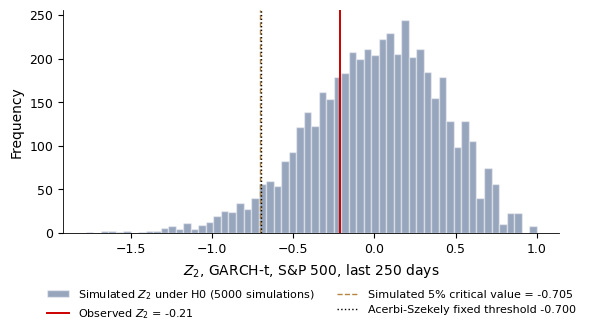

,MF_n,MF_mean,MF_t,MF_p,MF_p_normal,Z1,Z2,p2,crit5,T,Z2_last,p2_last,crit5_last,n_last
GARCH-t,198.0,0.100382,1.734315,0.0250,0.042213,-0.042023,-0.664211,0.0000,-0.151777,4959.0,-0.209913,0.2888,-0.704727,6.0
FHS,128.0,0.104292,1.343489,0.0718,0.090755,-0.044892,-0.078815,0.1906,-0.149695,4959.0,0.142033,0.6024,-0.710419,4.0
HS,156.0,0.363481,2.879161,0.0006,0.002276,-0.116912,-0.405430,0.0000,-0.153584,4959.0,0.722735,0.9754,-0.715814,2.0


In [ ]:
# Solution
def b3_es_sp500():
    out = {}
    for m in ('GARCH-t', 'FHS', 'HS'):
        require_es_complete('sp500',m)
        df = fc('sp500')[0][m]
        mf = mcneil_frey(df['L'].values, df['VaR2.5'].values, df['ES2.5'].values, df['scale'].values)
        z = z2_null('sp500', m)
        zl = z2_null('sp500', m, last=250)
        out[m] = dict(MF_n=mf['n'], MF_mean=mf['mean'], MF_t=mf['t'], MF_p=mf['p'],
                      MF_p_normal=float(stats.t.sf(mf['t'], mf['n'] - 1)),
                      Z1=z['Z1'], Z2=z['Z2'], p2=z['p'], crit5=z['crit5'], T=z['T'],
                      Z2_last=zl['Z2'], p2_last=zl['p'], crit5_last=zl['crit5'], n_last=zl['n_hit'])
        if m == 'GARCH-t':
            fig, ax = plt.subplots(figsize=(6.4, 2.9))
            ax.hist(zl['sims'], bins=60, color=MainBlue, alpha=0.45, edgecolor='white', label='Simulated $Z_2$ under H0 (5000 simulations)')
            ax.axvline(zl['Z2'], color=IDAred, lw=1.4, label=f'Observed $Z_2$ = {zl["Z2"]:.2f}')
            ax.axvline(zl['crit5'], color=Amber, ls='--', lw=1.0, label=f'Simulated 5% critical value = {zl["crit5"]:.3f}')
            ax.axvline(-0.70, color='black', ls=':', lw=1.0, label='Acerbi-Szekely fixed threshold -0.700')
            ax.set_xlabel(r'$Z_2$, GARCH-t, S&P 500, last 250 days')
            ax.set_ylabel('Frequency')
            legend_outside_bottom(ax, ncol=2, y=-0.2)
            save_fig('ch8_sem_z2_sim')
    return out


pd.DataFrame(b3_es_sp500()).T

### B7. $Z_2$ by simulation on the BET and the S&P 500 [Proposed]

- **Question**: are the ES 2.5% forecasts of GARCH-t and GARCH-EVT calibrated on the BET and on the S&P 500?

- **Worked example to follow**: [B3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3)

- **Inputs**

  - Forecast panels of the BET and the S&P 500 (both from 2007); Algorithm 2 of [B3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3) with 5000 draws, seed 11, forecasts held fixed

  - Samplers: GARCH-t as in [B3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3); GARCH-EVT $L^{*}=-\mu_t+\sigma_t\big(u+\frac{\beta}{\xi}\big[\big(\frac{1-U}{p_u}\big)^{-\xi}-1\big]\big)$ with the stored Generalised Pareto Distribution (GPD) threshold $u$, shape $\xi$, scale $\beta$ and share $p_u$ of standardised losses above $u$

- **Tasks**

  1.  On the full sample, build a table with one row per market and model (BET and S&P 500 $\times$ GARCH-t and GARCH-EVT): $Z_2$, $p$, 5% critical value, breach days.

  2.  Repeat on the last 250 days.

  3.  Plot the four null distributions with the observed $Z_2$.

- **Report**: the eight-row table and one figure

- **Interpretation**: a provisional comparison with its limitations: why does the verdict change between the full sample and the last year?

- Notebook section: [B7](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B7)

[Exercise B7 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B7)

Public replication benchmark: [Chapter 8, slide “Scorecard Across Four Markets”](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf#nameddest=ch8scorecard). Complete the additional tasks as well as reproducing the published figures.

In [ ]:
# Your code here


### B2. Is FHS significantly better? [Solved]

- **Question**: is FHS significantly better than GARCH-t, HS and GARCH-EVT under the FZ0 score on the S&P 500?

- **Inputs**

  - Daily FZ0 scores of (VaR 2.5%, ES 2.5%) for the six models on the S&P 500, aligned on the same 4 959 days ([Patton, Ziegel & Chen (2019)](https://doi.org/10.1016/j.jeconom.2018.10.008))

  - Score differential $d_t=S_{A,t}-S_{\mathrm{FHS},t}$ (a difference of scores, not of losses); Newey–West with $q=\lfloor 4(T/100)^{2/9}\rfloor=9$ lags, $\lfloor\cdot\rfloor$: integer part ([Newey & West (1987)](https://doi.org/10.2307/1913610))

- **Tasks**

  1.  Compute the mean FZ0 of each model.

  2.  For $A=$ GARCH-t: $\bar d$, the autocovariances $\gamma_0,\dots,\gamma_{9}$, $\mathrm{LRV}$ with $q=9$ ([“Comparing Two Forecasts: the Diebold–Mariano Test”](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=sem8p17)), $\mathrm{se}=\sqrt{\mathrm{LRV}/T}$, $\mathrm{DM}=\bar d/\mathrm{se}$ and its $p$-value ([Diebold & Mariano (1995)](https://doi.org/10.1080/07350015.1995.10524599)).

  3.  Repeat for HS and GARCH-EVT; compute the naive $t$ (ordinary standard error) and the ratio LRV$/\gamma_0$.

  4.  Plot the cumulative $d_t$, the Autocorrelation Function (ACF) of $d_t$ and the naive and Heteroskedasticity and Autocorrelation Consistent (HAC) 95% intervals of $\bar d$.

  5.  Optional: the Giacomini–White test with $h_{t-1}=(1,d_{t-1})$ ([Giacomini & White (2006)](https://doi.org/10.1111/j.1468-0262.2006.00718.x)).

- **Report**: mean scores, one complete Diebold–Mariano (DM) calculation, a DM table and one figure

- **Interpretation**

  - which differences are significant?

  - when does ignoring autocorrelation overstate significance?

- Notebook section: [B2](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B2)

1.  Mean FZ0: FHS $`-`$<!-- -->3.551, GARCH-EVT $`-`$<!-- -->3.548, GARCH-t $`-`$<!-- -->3.512, HS $`-`$<!-- -->3.134, Student-t $`-`$<!-- -->3.036, Normal $`-`$<!-- -->2.958.

2.  GARCH-t minus FHS: $\bar d=0.0388$; $\gamma_0=1.0076$; $\gamma_1,\dots,\gamma_9$: 0.0081, 0.0210, $`-`$<!-- -->0.0116, 0.0249, $`-`$<!-- -->0.0110, 0.0018, 0.0015, 0.0094, $`-`$<!-- -->0.0094.

3.  $2\sum_k(1-k/10)\gamma_k=0.0551$, so $\mathrm{LRV}=1.0627$; $\mathrm{se}=\sqrt{1.0627/4\,959}=0.0146$ (naive 0.0143).

4.  $\mathrm{DM}=0.0388/0.0146=2.65$, $p=0.008$: GARCH-t is significantly worse at 5%.

<div class="center">

| $A$ minus FHS | $\bar d$ | DM | $p$ | naive $t$ | LRV$/\gamma_0$ |
|:---|:--:|:--:|:--:|:--:|:--:|
| GARCH-t | 0.0388 | 2.65 | 0.008 | 2.72 | 1.05 |
| HS | 0.4173 | 4.70 | $<$0.001 | 7.18 | 2.34 |
| GARCH-EVT | 0.0029 | 1.24 | 0.216 | 1.31 | 1.11 |

</div>

- HS loses steadily and in jumps (2008, 2020); its LRV is 2.34 times $\gamma_0$, so the naive $t$ (7.18) overstates the HAC DM (4.70); for GARCH-t the ACF is small (lag 1: 0.008) and the two intervals almost coincide

- Provisional ranking: FHS and GARCH-EVT tie ($p=0.216$); GARCH-t and HS are significantly worse; Giacomini–White (GW) (optional): GARCH-EVT 7.38 ($p=0.025$): the conditional tie fails, which moment drives it needs a separate test

[Exercise B2 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B2)

Figures from the worked example: 

![ch8_sem_b2_dm](https://raw.githubusercontent.com/danpele/MFM/main/charts/ch8_sem_b2_dm.png)

In [ ]:
# Solution
def b2_dm_sp500():
    Lf = fz_losses('sp500')
    out = {}
    for a, b in (('GARCH-t', 'FHS'), ('HS', 'FHS'), ('GARCH-EVT', 'FHS')):
        d = Lf[a] - Lf[b]
        dm = diebold_mariano(Lf[a], Lf[b])
        naive = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
        out[f'{a}|{b}'] = dict(dbar=float(d.mean()), DM=dm['DM'], p=dm['p'], naive=float(naive),
                               lrv_ratio=float(nw_var(d.values) / d.var()))
    out['mean'] = {m: float(v) for m, v in Lf.mean().items()}
    out['T'] = len(Lf)
    out['lags'] = int(np.floor(4 * (len(Lf) / 100) ** (2 / 9)))
    return out


b2_dm_sp500()

{'GARCH-t|FHS': {'dbar': 0.039799723938516975,
  'DM': np.float64(2.656408862845489),
  'p': np.float64(0.00789777952367373),
  'naive': 2.7301256580910653,
  'lrv_ratio': 1.0562711839539676},
 'HS|FHS': {'dbar': 0.4166802415212664,
  'DM': np.float64(4.6900059396425835),
  'p': np.float64(2.731971183969679e-06),
  'naive': 7.164830997099296,
  'lrv_ratio': 2.3338079564782914},
 'GARCH-EVT|FHS': {'dbar': 0.0028644951960696036,
  'DM': np.float64(1.2437377875548508),
  'p': np.float64(0.21359608375231431),
  'naive': 1.3152372569070316,
  'lrv_ratio': 1.1182799712960245},
 'mean': {'HS': -3.134042841441771,
  'Normal': -2.9578279082047287,
  'Student-t': -3.036176263201934,
  'GARCH-t': -3.5109233590245204,
  'FHS': -3.5507230829630374,
  'GARCH-EVT': -3.547858587766968},
 'T': 4959,
 'lags': 9}

In [ ]:
# Solution, B2 sub-task 5 (optional): Giacomini-White conditional test
def b2_gw_sp500():
    """Conditional Giacomini-White test on the FZ0 differentials against FHS."""
    Lf = fz_losses('sp500')
    return {f'{a}|FHS': gw_test(Lf[a], Lf['FHS']) for a in ('GARCH-t', 'HS', 'GARCH-EVT')}


b2_gw_sp500()

{'GARCH-t|FHS': {'W': 7.59742142833674,
  'p': 0.02239963277635226,
  'unc': 2.728350912912752,
  'p_unc': 0.006365185553643383},
 'HS|FHS': {'W': 53.15652641580683,
  'p': 2.8655431347405086e-12,
  'unc': 7.128743282903121,
  'p_unc': 1.0128944490685561e-12},
 'GARCH-EVT|FHS': {'W': 6.708091929138209,
  'p': 0.034942690822775256,
  'unc': 1.3151404814779128,
  'p_unc': 0.18846269371804547}}

### B8. Comparing models on the BET and the S&P 500 [Proposed]

- **Question**: can the data separate the six models on the BET and on the S&P 500?

- **Worked example to follow**: [B2](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B2)

- **Inputs**

  - Daily FZ0 scores of the six models on the BET and on the S&P 500; DM with Newey–West lags $\lfloor 4(T/100)^{2/9}\rfloor$

  - Model Confidence Set (MCS) ([Hansen, Lunde & Nason (2011)](https://doi.org/10.3982/ECTA5771)): $T_{max}$ statistic (the largest standardised mean loss differential among the models still in the set), circular block bootstrap, blocks of 10 days, 1000 replications, seed 2, 90% set

  - Murphy diagram ([Ehm, Gneiting, Jordan & Krüger (2016)](https://doi.org/10.1111/rssb.12154)): BET VaR 2.5%, HS versus GARCH-EVT, 240 thresholds from 1.0% to 7.3%, pointwise HAC bands with the same automatic lag rule as DM

- **Tasks**

  1.  Find the lowest mean FZ0 in each market and run exploratory DM tests of every other model against it.

  2.  Run the MCS; show the first elimination step (statistic, $p$-value, model removed) and list the 90% set.

  3.  Plot the Murphy difference with its bands and say whether the curves cross.

- **Report**: a DM/MCS table, the elimination steps, one figure

- **Interpretation**

  - which models remain in the MCS for each market?

  - what limits the separation?

- Notebook section: [B8](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B8)

[Exercise B8 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B8)

The MCS helper is defined in the lecture notebook common-functions section. [Notebook](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/EN/chapter8_lecture_notebook.ipynb).

Public replication benchmark: [Chapter 8, slide “Which Models Survive?”](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf#nameddest=ch8mcsretained). Complete the additional tasks as well as reproducing the published figures.

In [ ]:
# Your code here


### B4. Conformal VaR in calm and crisis periods [Solved] — after the lecture

- **Question**: does split conformal VaR keep its coverage on crisis days of the S&P 500?

- **Inputs**

  - Timeline for forecast day $t$ (all windows end at $t-1$): scale $\hat\sigma_t$ = standard deviation of $r_{t-250},\dots,r_{t-1}$; calibration scores $s_{t-250},\dots,s_{t-1}$, $s_j=L_j/\hat\sigma_j$; crisis flag: standard deviation of $r_{t-20},\dots,r_{t-1}$ above the 90th percentile of its values over the previous 1000 days

  - Split conformal VaR in [“Tools for B4: Split Conformal VaR”](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=sem8p20) with $n=250$; evaluation 03.01.2007–18.09.2026 (4 959 days); benchmark: i.i.d. Student-$t_4$ returns $\times 1\%$, seed 5, same length

- **Tasks**

  1.  Build VaR 5% and VaR 1% and the breach series on the S&P 500.

  2.  Fill the grid (data source $\times$ level $\times$ all/calm/crisis) with rates and counts; add the Kupiec $p$ (all days) and the Christoffersen independence $p$.

  3.  Repeat on the i.i.d. benchmark series: its returns are exchangeable, but the scores standardised on a rolling window are only approximately exchangeable.

  4.  Plot a VaR path with crisis shading and the rates with their binomial intervals.

- **Report**: the grid, two $p$-values per series, one figure

- **Interpretation**

  - is the marginal guarantee met on real data?

  - what changes between real and exchangeable data: coverage or independence?

- Notebook section: [B4](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B4)

- S&P 500, VaR 5%: all 265/4 959 = 5.34% (Kupiec $p=0.272$), calm 213/4 246 = 5.02%, crisis 52/713 = 7.29%; independence rejected ($p$ $<$0.001); VaR 1%: 1.29% overall ($p=0.049$), 2.10% in crises

- i.i.d. benchmark: 4.74%, calm 4.68%, crisis 5.26% (27/513), independence not rejected ($p=0.965$); the binomial intervals ignore dependence, so the real-data ones are too narrow

- Interpretation: the average is close to 5%, but volatility clustering breaks exchangeability, so breaches cluster and crisis coverage fails

[Exercise B4 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B4)

Wald 95% interval: $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/T}$. This is a binomial reference interval; dependence between exceptions can invalidate its nominal interpretation.

Figures from the worked example: 

![ch8_sem_b4_conformal](https://raw.githubusercontent.com/danpele/MFM/main/charts/ch8_sem_b4_conformal.png)

In [ ]:
# Solution
def b4_conformal_sp500():
    out = {}
    for a in (0.05, 0.01):
        r = load_returns('sp500')
        c = conformal_var(r, a=a).loc[fc('sp500')[0]['HS'].index[0]:]
        validate_conformal_frame(c,*canonical_sample('sp500'))
        reg = regimes(r, c.index)
        hs = c['L'] > c['VaR_split']
        # simulation: same procedure on i.i.d. Student-t returns (exchangeable returns; rolling scores only approximately)
        rng = np.random.default_rng(5)
        x = pd.Series(rng.standard_t(4, len(r)) * 0.01, index=r.index)
        ci = conformal_var(x, a=a).loc[c.index[0]:]
        regi = regimes(x, ci.index)
        hi = ci['L'] > ci['VaR_split']
        out[str(a)] = dict(T=len(c), rate=float(hs.mean()), calm=float(hs[~reg].mean()), crisis=float(hs[reg].mean()),
                           kup=kupiec(hs.values, a)['p'], iid_rate=float(hi.mean()), iid_calm=float(hi[~regi].mean()),
                           iid_crisis=float(hi[regi].mean()), n_crisis=int(reg.sum()),
                           ind=christoffersen(hs.values, a)['p_ind'], ind_iid=christoffersen(hi.values, a)['p_ind'])
    return out


pd.DataFrame(b4_conformal_sp500()).T

,T,rate,calm,crisis,kup,iid_rate,iid_calm,iid_crisis,n_crisis,ind,ind_iid
0.05,4959.0,0.053438,0.050165,0.072931,0.271685,0.047389,0.046784,0.052632,713.0,0.000032,0.965171
0.01,4959.0,0.012906,0.011540,0.021038,0.049029,0.007260,0.007197,0.007797,713.0,0.001386,0.468031


### B6. Conformal VaR on the BET and Bitcoin [Proposed]

- **Question**: does ACI repair crisis coverage on the BET and on Bitcoin, or only the long-run average?

- **Worked example to follow**: [B4](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B4)

- **Inputs**

  - BET daily closes from 03.01.2007 and Bitcoin daily closes (24:00 Coordinated Universal Time (UTC)) from 14.06.2017, to 18.09.2026; VaR 5%: split conformal and ACI on both markets, GARCH-t on the BET only (GARCH forecasts on Bitcoin are withheld, [Chapter 8](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf)); scores, windows and crisis flag as in [B4](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B4)

  - ACI: $\alpha_1=0.05$, $\gamma=0.005$, started on the first evaluation day; an infinite VaR counts as no breach and is reported separately

- **Tasks**

  1.  For each market and method, report breach counts and rates on all, calm and crisis days.

  2.  Report the number of days with an infinite ACI VaR.

  3.  Attach the Wald binomial 95% interval of [B4](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B4) (which ignores dependence) to each crisis rate and say which differences from 5% are clear.

- **Report**: a rate-and-count table, the infinite-VaR count, one figure

- **Interpretation**: an evidence-qualified comparison of the three methods, not a single winner

- Notebook section: [B6](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B6)

[Exercise B6 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B6)

Public replication benchmark: [Chapter 8, slide “Coverage in Calm and Crisis Periods”](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf#nameddest=ch8calmcrisis). Complete the additional tasks as well as reproducing the published figures.

In [ ]:
# Your code here


### B9. Kupiec size under estimation risk [Proposed]

- **Question**: how often does Kupiec reject a correct GARCH-t model when its parameters are estimated?

- **Worked example to follow**: [B1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B1)

- **Inputs**

  - Fixed Data-Generating Process (DGP): GARCH(1,1)-t fitted to the S&P 500 1990–2026 ($a=0.102$, $b=0.892$, $\nu=6.1$); 400 paths of $R+5000$ days after a burn-in of 500, seed 9

  - Fixed scheme: estimate once on the first $R=1000$ days ($\nu$ floored at 2.2), then forecast VaR 1% for $P=250$, 1000, 5000 days; on the same path also the true-parameter VaR

  - A path whose fit is not clearly admissible ($\hat a+\hat b$ at the boundary $1$ within $10^{-8}$, or a failed fit) has no estimated forecast and is left out

- **Tasks**

  1.  Count the paths with an admissible fit; on them, record the Kupiec rejection at 5% for the estimated and the true forecasts, paired on each path.

  2.  Also report the true-parameter rate on all paths: does the selection change it?

  3.  Report each rejection rate with its own Monte Carlo standard error $\sqrt{\hat p(1-\hat p)/n}$, $\hat p$: the rejection rate, $n$: the number of paths used.

  4.  Compare the standard deviation of the breach rate across paths with $\sqrt{\alpha(1-\alpha)/P}$; plot the rates against $P/R$.

  5.  Going further: an actual bootstrap calibration: simulate under the fitted null, re-estimate on each replicate and take the 95th percentile of $\mathrm{LR}_{uc}$ as the critical value.

- **Report**: a table ($P$, two rates with standard errors, two standard deviations) and one figure

- **Interpretation**: how does the distortion grow with $P/R$ ([Escanciano & Olmo (2010)](https://doi.org/10.1198/jbes.2009.07063))?

- Notebook section: [B9](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B9)

[Exercise B9 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B9)

Full DGP vector, in decimal log returns:
```python
par = (0.0007491951213314657, 1.2150511439130614e-6, 0.10233294961419648, 0.8921133418387606, 6.1450454469424685)  # mu, omega, alpha, beta, nu
```
Initial variance is omega/(1-alpha-beta). Scale Student-t innovations by sqrt((nu-2)/nu), and discard the first 500 returns. After re-estimation initialise the filter with the divisor-50 variance of the first 50 estimation returns.

Public replication benchmark: [Chapter 8, slide “Estimation Risk: Simulation Results”](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf#nameddest=ch8estsim). Complete the additional tasks as well as reproducing the published figures.

In [ ]:
# Your code here


## Part C — open questions and AI critique

### C2. A provisional model for a Romanian trading portfolio [Proposed]

- **Question**: which VaR/ES model would you provisionally recommend for a portfolio in lei, half in the BET and half in euro?

- **Inputs**

  - BET daily closes and the BNR EUR/RON reference rate; align the **prices** on common trading days, then simple returns, then the portfolio log return $r^p_t=\ln(1+\tfrac12R^{BET}_t+\tfrac12R^{EUR}_t)$ ($R$: simple returns), daily rebalanced, no costs

  - The six models of [Chapter 8](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf) (window of 1 000 days); evaluation from 09.07.2009 (after 2008: the 2008 crisis enters estimation windows but is outside the evaluation sample) to 18.09.2026

- **Tasks**

  1.  Build the portfolio and plot its losses with the VaR 1% of HS, FHS and GARCH-EVT.

  2.  Run the minimum test set (below) for all six models.

- Notebook section: [C2](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-C2)

- **Questions**

  - what does the evidence support?

  - what does it not support?

- **Worked example to follow**: [B1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B1)–[B3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3), [B5](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B5), [B7](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B7)

- **Inputs**: minimum test set: frequency (Kupiec, CC), timing (durations or DQ), ES ($Z_2$ by simulation), comparison (FZ0, DM, 90% MCS), regulation (worst and last 250-day windows, desk limits)

- **Tasks**

  1.  Fill the evidence table: model $\times$ rate, $p_{cc}$, $p_{dur}$, $Z_2$ / $p$, worst window, last window (VaR 1% / VaR 2.5%), FZ0 / MCS $p$.

  2.  For each test report simulated size at $T=250$ ([B1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B1)); for the frequency test compute power at breach rate $2\alpha$ as in [A1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A1). Discuss the family-wise false-alarm rate; individual 5% sizes do not imply a 5% rate for the set.

  3.  Write one provisional recommendation with a challenger model, and list what FRTB approval would also require (desk P&L backtests, P&L attribution).

- **Report**: a Quantlet folder and one slide: figure, evidence table, recommendation, main limitation

- **Interpretation**: would the choice survive a year like 2008 or 2020?

- Notebook section: [C2](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-C2)

[Exercise C2 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-C2)

In [ ]:
# Your code here


### C1. Critique an AI answer [Proposed]

- **Questions**

  - is the AI answer below correct?

  - does its conclusion survive once the code is fixed?

- **Worked example to follow**: [A2](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A2), [A3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A3)

- **Inputs**

  - The prompt, the answer and its line-numbered code (below); $\texttt{lr\_ind(I)}$ is `christoffersen(I, 0.01)[’LR_ind’]` from the notebook helpers

  - Test series: 401 prices from 100, daily log returns $0.01\times t_4/\sqrt2$ (seed 8) with $r=-8\%$ at return-array index 320 (0-based); real data: S&P 500 daily closes from 1990

- **Tasks**

  1.  Find the three conceptual errors: in the forecast window, in the test distribution, in the regulatory reading.

  2.  For each error, say how you would detect it: by a numerical check of the output, by the formulas of [Chapter 8](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf), or by a published table (BCBS).

  3.  Run the answer’s code and your corrected code on the test series and on the S&P 500; report $\mathrm{VaR}$ for return index 320 (zero-based, VaR\[70\] when W=250) and the exception counts.

  4.  Give the correct zone, plus factor and multiplier for 7 exceptions ([A3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-A3)).

  5.  Optional checks: the evaluation window of the traffic light; $x=0$ in the Kupiec formula.

- **Report**: the three errors with detection and correction, the corrected code, four exception counts (two codes on two series)

- **Interpretation**: does “the model must be withdrawn” survive?

- Notebook section: [C1](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-C1)

**Supplied response to audit (contains deliberate errors)**

- **Prompt**: “I have daily S&P 500 closes in a pandas Series `P`. Write Python for a rolling 250-day historical-simulation VaR 1%, count the exceptions and run the Kupiec and Christoffersen tests. My last 250 days have 7 exceptions: what does that mean?”

``` numberLines
import numpy as np, scipy.stats as stats
r = np.log(P).diff().dropna().values
W, p = 250, 0.01
VaR = np.array([-np.quantile(r[t-W:t+1], p) for t in range(W, len(r))])
I = (-r[W:] > VaR).astype(int)
T, x = len(I), I.sum(); ph = x / T
LR_uc = -2*((T-x)*np.log(1-p) + x*np.log(p) - (T-x)*np.log(1-ph) - x*np.log(ph))
LR_cc = LR_uc + lr_ind(I)
p_uc, p_cc = stats.chi2.sf(LR_uc, df=1), stats.chi2.sf(LR_cc, df=1)
```

- **Answer**: “Your last 250 days: $x=7$, $\mathrm{LR}_{uc}=5.50$, $p=0.019$: coverage rejected at 5%. Under the Basel traffic light 7 exceptions is the red zone, so the model must be withdrawn.”

- AI code usually runs without an error message: the mistakes are in the finance and the statistics, not in the syntax

[Exercise C1 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-C1)

In [ ]:
# Input for C1: the test price series
def c1_fixture(n=400, day=320, shock=-0.08, seed=8):
    """C1 test price series: 400 returns and 401 prices from 100, daily log returns 1% x standardised Student-t4, seed 8,
    with a return of -8% on day 320."""
    rng = np.random.default_rng(seed)
    r = 0.01 * rng.standard_t(4, n) / np.sqrt(2)
    r[day] = shock
    P = 100 * np.exp(np.r_[0, np.cumsum(r)])
    return P


P_test = c1_fixture()
print(len(P_test), round(P_test[0], 2))

401 100.0


In [ ]:
# Work here: the answer's code and your corrected code


### C3. Backtesting ES with ES forecasts only [Proposed]

- **Question**: do the regression-based ES backtests of [Bayer & Dimitriadis (2022)](https://doi.org/10.1093/jjfinec/nbaa013) agree with $Z_2$ and McNeil–Frey on the [Chapter 8](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf) forecasts?

- **Inputs**

  - The available ES 2.5% forecasts: six models on the S&P 500 and the BET; HS, Normal and Student-t on Bitcoin and EUR/RON (18 series; GARCH forecasts on Bitcoin and EUR/RON are withheld); returns convention of the paper: $r_t=-L_t$, $\hat e_t=-\widehat{\mathrm{ES}}_t<0$

  - R (4.x) with the authors’ package: `esback::esr_backtest(r, e, alpha = 0.025, version = v)`; $v=1$: Strict Expected Shortfall Regression (ESR) (two-sided), $v=3$: Intercept ESR (one-sided $H_0$: $\gamma_1\ge 0$, $\gamma_1$: intercept of $r_t-\hat e_t$, negative when ES is underestimated); misspecification-robust covariance (default)

- **Tasks**

  1.  Work one case first: S&P 500, GARCH-t: print the coefficients, their standard errors, the statistic and the $p$-value of both versions.

  2.  Run both versions on all 18 series and draw a market-by-model heat map of the $p$-values.

  3.  Compare the decisions at 5% with $Z_2$ and McNeil–Frey ([Chapter 8](https://danpele.github.io/MFM/EN/Courses/chapter8_backtesting_risk.pdf), section “Backtesting Expected Shortfall”).

- Notebook section: [C3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-C3)

- **Questions**

  - how do the tests behave on one-year blocks?

  - what is their size at $T=250$?

- **Worked example to follow**: [B3](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-B3)

- **Inputs**: non-overlapping 250-day blocks of the S&P 500 from the first evaluation day (drop the incomplete last block); the Exponential GARCH (EGARCH)(1,1)-t process of Eq. 2.1 of the paper, 1000 paths, seeds 1 through 1000

- **Tasks**

  1.  Report the share of blocks in which each model is rejected, and the number of failed fits (excluded from the share).

  2.  Simulate 1000 paths of 250 days, backtest the true ES 2.5% with the Intercept ESR, two-sided and one-sided, and report the rejection rates with their Monte Carlo standard errors.

  3.  Compare the two-sided rate with the 0.04 of Table 1 (robust covariance) and the one-sided rate with the nominal 5% (Table 2 reports it only at $T=2\,500$).

- **Report**: a Quantlet folder and two slides: the decision heat map with $Z_2$ and McNeil–Frey, and the block shares with the size check

- **Interpretation**

  - when ESR and $Z_2$ disagree, which would you trust as a supervisor who receives only ES forecasts?

  - why would you trust it?

[Exercise C3 in the seminar](https://danpele.github.io/MFM/EN/Seminars/seminar8_backtesting_risk.pdf#nameddest=ex-C3)

Simulation specification: $\log\sigma_t^2$ coefficients (rugarch parameter names) $(\omega,\alpha_1,\gamma_1,\beta_1)=(-0.0012,-0.161,0.136,0.978)$; `rugarch` distribution `std`, df=7.39; `ugarchpath(n.start=100,n.sim=750)`, discard first 500, evaluate final 250. Report the package version and failed fits.

In [ ]:
# Input for C3: export returns and ES forecasts for R
for mk in ('sp500', 'bet', 'btc', 'eurron'):
    F, _, _, _ = es_inputs(mk)
    out = pd.DataFrame({m: -F[m]['ES2.5'] for m in F})
    out.insert(0, 'r', -F['GARCH-t']['L'])
    out.to_csv(f'c3_{mk}.csv')
    print(mk, out.shape)
    availability=pd.DataFrame({m:F[m]['ES2.5'].notna() for m in MODELS},index=out.index)
    availability.to_csv(f'c3_{mk}_availability.csv')
    print('Unavailable ES rows per model (kept on original calendar):',(~availability).sum().to_dict())
    print('Do not treat missing ES as zero or silently drop rows for full-sample tests.')


sp500 (4959, 7)
Unavailable ES rows per model (kept on original calendar): {'HS': 0, 'Normal': 0, 'Student-t': 0, 'GARCH-t': 0, 'FHS': 0, 'GARCH-EVT': 0}
Do not treat missing ES as zero or silently drop rows for full-sample tests.
bet (4937, 7)
Unavailable ES rows per model (kept on original calendar): {'HS': 0, 'Normal': 0, 'Student-t': 0, 'GARCH-t': 0, 'FHS': 0, 'GARCH-EVT': 0}
Do not treat missing ES as zero or silently drop rows for full-sample tests.


GARCH numerical status: {'policy': 'finite-variance-resolution-1e-8-v1', 'refits_by_status': {'clearly-admissible': 43, 'numeric-unidentified': 119, 'finite-variance-inadmissible': 8, 'fit-invalid': 0}, 'fallback_forecast_days': 880, 'max_parameter_age_trading_rows': 379, 'age_definition': 'trading rows since source refit origin; variance/residuals filtered on current data', 'no_previous_fit': 'dependent forecasts missing; original calendar and independent forecasts preserved', 'unavailable_forecast_days': 1660, 'unavailable_refits': 83}
Fallback parameters are stale; filtering still uses current observations.
                       fallback_days  max_age
parameter_source_date                        
2022-10-06                        40     59.0
2022-12-05                       340    359.0
2023-11-30                       360    379.0
2024-12-14                        20     39.0
2025-07-22                        80     99.0
2026-02-27                        40     59.0
btc (3384, 7)


GARCH numerical status: {'policy': 'finite-variance-resolution-1e-8-v1', 'refits_by_status': {'clearly-admissible': 46, 'numeric-unidentified': 162, 'finite-variance-inadmissible': 10, 'fit-invalid': 0}, 'fallback_forecast_days': 3412, 'max_parameter_age_trading_rows': 1359, 'age_definition': 'trading rows since source refit origin; variance/residuals filtered on current data', 'no_previous_fit': 'dependent forecasts missing; original calendar and independent forecasts preserved', 'unavailable_forecast_days': 20, 'unavailable_refits': 1}
Fallback parameters are stale; filtering still uses current observations.
                       fallback_days  max_age
parameter_source_date                        
2009-10-29                       560    579.0
2012-02-07                      1020   1039.0
2018-11-05                        20     39.0
2019-05-03                      1340   1359.0
2024-09-30                       472    491.0
eurron (4352, 7)
Unavailable ES rows per model (kept on orig